# Notebook 01 — Data Collection for CAMP

**Project:** Calibration-Aware ML-Predictive Scheduling for Single-GPU LLM Inference  
**Environment:** Google Colab + NVIDIA Tesla T4  
**LLM:** `Qwen/Qwen2.5-1.5B-Instruct` served by vLLM

## What this notebook does

1. Checks the Colab GPU and installs the required runtime packages (only if missing).
2. Starts Qwen through vLLM's OpenAI-compatible local server.
3. Generates steady, mixed and bursty request workloads.
4. Collects real request-level timings and GPU telemetry.
5. Saves two files:
   - `latency_dataset.csv` — measured examples for training the latency predictor.
   - `benchmark_traces.csv` — separate, not-yet-executed requests for the later four-scheduler comparison.

**No GUI, dashboard or separate application is used.** Results appear directly below the notebook cells.

> This is the initial pilot collection. After validating the pipeline, increase the run sizes/repetitions before treating the data as final research evidence. Do not report illustrative or pilot metrics as final results.

> **Token-counting fix:** Current Transformers releases may return a dictionary-like `BatchEncoding` from `apply_chat_template`. Calling `len()` on that object counts dictionary fields (often 2), not tokens. This notebook explicitly sets `return_dict=False` and validates the resulting token-count distribution before saving any CSV.


## Cell 1 — Check the GPU

Select **Runtime → Change runtime type → T4 GPU** before running this notebook.

In [1]:
import subprocess, platform, torch, sys

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU is not enabled. In Colab, choose Runtime > Change runtime type > T4 GPU.")

print("GPU:", torch.cuda.get_device_name(0))
print("Compute capability:", torch.cuda.get_device_capability(0))
print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
print(subprocess.check_output(["nvidia-smi"], text=True))

Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
Compute capability: (7, 5)
GPU memory (GiB): 14.56
Tue Nov 24 14:25:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|               

## Cell 2 — Install packages if needed

The vLLM CUDA 13.0 installation command below follows the current vLLM GPU installation documentation. If vLLM is already installed, this cell skips reinstalling it. If it installs vLLM now, **restart the Colab runtime once**, then continue from Cell 1.

In [2]:
import importlib.util, subprocess, sys

if importlib.util.find_spec("vllm") is None:
    print("Installing vLLM for CUDA 13.0. This may take several minutes...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "vllm",
        "--extra-index-url", "https://download.pytorch.org/whl/cu130"
    ])
    print("vLLM installation finished. Restart the Colab runtime, then rerun this notebook.")
else:
    print("vLLM is already installed; skipping installation.")

missing = [p for p in ["openai", "transformers", "pandas", "requests"]
           if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Installed:", ", ".join(missing))
else:
    print("Client/data packages are already installed.")

Installing vLLM for CUDA 13.0. This may take several minutes...
vLLM installation finished. Restart the Colab runtime, then rerun this notebook.
Client/data packages are already installed.


## Cell 3 — Configure and start the Qwen vLLM server

The pilot uses FP16, a 2,048-token context limit and at most four simultaneous sequences to stay conservative on the T4. If startup fails, inspect the printed log before changing settings.

In [3]:
import os, sys, time, shutil, subprocess, requests
from pathlib import Path

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
SERVER_HOST = "127.0.0.1"
SERVER_PORT = 8000
BASE_URL = f"http://{SERVER_HOST}:{SERVER_PORT}/v1"
SERVER_LOG_PATH = "/content/vllm_server.log"

# Reuse an already-running local server if it responds to the health check.
server_ready = False
try:
    server_ready = requests.get(f"http://{SERVER_HOST}:{SERVER_PORT}/health", timeout=3).status_code == 200
except Exception:
    server_ready = False

server_process = None
server_log_handle = None

if not server_ready:
    vllm_executable = shutil.which("vllm")
    if not vllm_executable:
        raise RuntimeError("The vLLM command was not found. Run the installation cell, restart the runtime, and try again.")

    command = [
        vllm_executable, "serve", MODEL_ID,
        "--dtype", "half",
        "--max-model-len", "2048",
        "--max-num-seqs", "4",
        "--gpu-memory-utilization", "0.85",
        "--host", SERVER_HOST,
        "--port", str(SERVER_PORT)
    ]
    server_log_handle = open(SERVER_LOG_PATH, "w")
    server_process = subprocess.Popen(command, stdout=server_log_handle, stderr=subprocess.STDOUT)
    print("Started vLLM. Waiting for model download and server startup...")

    deadline = time.time() + 900
    while time.time() < deadline:
        if server_process.poll() is not None:
            break
        try:
            r = requests.get(f"http://{SERVER_HOST}:{SERVER_PORT}/health", timeout=3)
            if r.status_code == 200:
                server_ready = True
                break
        except Exception:
            pass
        time.sleep(5)

if not server_ready:
    print("\n--- Last 100 lines of vLLM log ---")
    if Path(SERVER_LOG_PATH).exists():
        print("\n".join(Path(SERVER_LOG_PATH).read_text(errors="ignore").splitlines()[-100:]))
    raise RuntimeError("vLLM did not become ready. Check the log above before continuing.")

print("vLLM server is ready:", BASE_URL)
print("Server log:", SERVER_LOG_PATH)

Started vLLM. Waiting for model download and server startup...
vLLM server is ready: http://127.0.0.1:8000/v1
Server log: /content/vllm_server.log


## Cell 4 — Connect to Qwen and load its tokenizer

The tokenizer is used to record actual prompt/output token counts. vLLM exposes an OpenAI-compatible chat-completions endpoint.

In [4]:
from openai import AsyncOpenAI
from transformers import AutoTokenizer

client = AsyncOpenAI(base_url=BASE_URL, api_key="EMPTY", timeout=600.0, max_retries=0)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)

models = await client.models.list()
print("Available model IDs:", [m.id for m in models.data])

# Small single-request smoke test before collecting the dataset.
smoke = await client.chat.completions.create(
    model=MODEL_ID,
    messages=[{"role": "user", "content": "In one sentence, what is LLM inference scheduling?"}],
    max_tokens=40,
    temperature=0
)
print("\nQwen response:\n", smoke.choices[0].message.content)

Available model IDs: ['Qwen/Qwen2.5-1.5B-Instruct']

Qwen response:
 LLM inference scheduling refers to the process of managing and optimizing the execution of language model inferencing tasks across multiple devices or servers.


## Cell 5 — Define pilot workloads and request prompts

We use three open-loop arrival patterns:

- **steady:** regular request arrivals.
- **mixed:** variable Poisson-style arrival gaps.
- **bursty:** short groups of requests followed by pauses.

Prompt lengths and requested output limits vary in every workload. The three repeats use client concurrency limits 1, 2 and 4, so the predictor sees different load levels. Each prompt includes a unique request ID to avoid repeatedly submitting identical prompt prefixes.

In [5]:
import random, numpy as np, pandas as pd, json, uuid
from collections import deque

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Pilot settings. Increase these only after the first end-to-end run succeeds.
REQUESTS_PER_RUN = 20
REPEATS_PER_WORKLOAD = 3
CONCURRENCY_LEVELS = [1, 2, 4]  # T4 pilot; vLLM is configured with max-num-seqs=4
PROMPT_TARGET_CHOICES = [32, 128, 256, 512]
OUTPUT_LIMIT_CHOICES = [32, 64, 96]
WORKLOAD_TYPES = ["steady", "mixed", "bursty"]

TEXT_BANK = [
    "Large language model serving systems receive requests with different prompt sizes and generation limits.",
    "A request scheduler manages waiting jobs and decides when each request is sent to the inference engine.",
    "GPU memory is shared by model weights, intermediate activations and the key value cache used during decoding.",
    "The prefill phase processes input tokens while the decode phase generates output tokens sequentially.",
    "Throughput, tail latency and goodput are important measurements for an online inference service.",
    "A burst of requests can increase queue depth and change the latency experienced by later requests.",
    "An admission controller can limit the number of active requests without modifying the inference backend.",
    "A workload trace records arrival times, prompt lengths and requested output token limits for reproducible tests."
]

def build_prompt(target_tokens: int, request_id: str, rng: random.Random):
    """Build a varied prompt and return its actual chat-template token count."""
    pieces = [f"Request reference {request_id}."]
    content = " ".join(pieces)
    target_content_tokens = max(8, target_tokens - 20)
    while len(tokenizer.encode(content, add_special_tokens=False)) < target_content_tokens:
        pieces.append(rng.choice(TEXT_BANK))
        content = " ".join(pieces)
    content_ids = tokenizer.encode(content, add_special_tokens=False)[:target_content_tokens]
    content = tokenizer.decode(content_ids, skip_special_tokens=True)
    messages = [{"role": "user", "content": content + "\nGive a concise, relevant answer."}]
    # Transformers' current API can return a dictionary-like BatchEncoding by default.
    # len(BatchEncoding) counts its keys (commonly 2), NOT the number of token IDs.
    # Explicitly request a plain list of token IDs so len(...) is the true token count.
    prompt_ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=False
    )
    actual_prompt_tokens = len(prompt_ids)
    if actual_prompt_tokens <= 2:
        raise RuntimeError(
            f"Invalid chat-template token count ({actual_prompt_tokens}). "
            "Check tokenizer output and Transformers version before collecting data."
        )
    return messages, actual_prompt_tokens, content

def make_arrival_offsets(n: int, workload_type: str, rng: np.random.Generator):
    if workload_type == "steady":
        offsets = np.arange(n, dtype=float) * 0.60
    elif workload_type == "mixed":
        gaps = rng.exponential(scale=0.60, size=n)
        offsets = np.cumsum(gaps) - gaps[0]
    elif workload_type == "bursty":
        offsets = []
        for i in range(n):
            burst_number, within_burst = divmod(i, 5)
            offsets.append(burst_number * 3.0 + within_burst * 0.06)
        offsets = np.asarray(offsets, dtype=float)
    else:
        raise ValueError(f"Unknown workload type: {workload_type}")
    return offsets

def make_request_specs(workload_type: str, run_id: str, n: int, seed: int):
    py_rng = random.Random(seed)
    np_rng = np.random.default_rng(seed)
    offsets = make_arrival_offsets(n, workload_type, np_rng)
    specs = []
    for i in range(n):
        request_id = f"{run_id}_req_{i:04d}"
        target_prompt = py_rng.choice(PROMPT_TARGET_CHOICES)
        max_output = py_rng.choice(OUTPUT_LIMIT_CHOICES)
        messages, actual_prompt_tokens, prompt_text = build_prompt(target_prompt, request_id, py_rng)
        specs.append({
            "request_id": request_id,
            "run_id": run_id,
            "workload_type": workload_type,
            "arrival_offset_s": float(offsets[i]),
            "prompt_text": messages[0]["content"],
            "prompt_tokens": int(actual_prompt_tokens),
            "max_output_tokens": int(max_output)
        })
    return specs

print("Pilot configuration")
print("Requests per run:", REQUESTS_PER_RUN)
print("Repeats per workload:", REPEATS_PER_WORKLOAD)
print("Total measured requests:", REQUESTS_PER_RUN * REPEATS_PER_WORKLOAD * len(WORKLOAD_TYPES))
print("Concurrency levels across repeated runs:", CONCURRENCY_LEVELS)

# Token-count sanity check before generating any data.
_test_messages = [{"role": "user", "content": "Count this sample prompt as more than two tokens."}]
_test_ids = tokenizer.apply_chat_template(
    _test_messages, tokenize=True, add_generation_prompt=True, return_dict=False
)
print("Token-count sanity check:", len(_test_ids), "tokens")
if len(_test_ids) <= 2:
    raise RuntimeError("Tokenizer sanity check failed; do not collect data.")


Pilot configuration
Requests per run: 20
Repeats per workload: 3
Total measured requests: 180
Concurrency levels across repeated runs: [1, 2, 4]
Token-count sanity check: 39 tokens


## Cell 6 — Start GPU telemetry sampling

GPU utilisation and memory are sampled in the background approximately once per second. Each request uses the latest sample available at its admission time; this is an approximate telemetry snapshot, not a per-kernel measurement.

In [6]:
import threading, time, subprocess

_gpu_stop = threading.Event()
_gpu_lock = threading.Lock()
_gpu_samples = []

def _gpu_sampler():
    while not _gpu_stop.is_set():
        try:
            result = subprocess.check_output([
                "nvidia-smi",
                "--query-gpu=utilization.gpu,memory.used,memory.total",
                "--format=csv,noheader,nounits"
            ], text=True, stderr=subprocess.DEVNULL, timeout=5)
            parts = [x.strip() for x in result.strip().split(",")]
            if len(parts) >= 3:
                sample = {
                    "sampled_at_perf": time.perf_counter(),
                    "gpu_utilization_pct": float(parts[0]),
                    "gpu_memory_used_mib": float(parts[1]),
                    "gpu_memory_total_mib": float(parts[2])
                }
                with _gpu_lock:
                    _gpu_samples.append(sample)
                    if len(_gpu_samples) > 5000:
                        del _gpu_samples[:1000]
        except Exception:
            pass
        _gpu_stop.wait(1.0)

def latest_gpu_sample():
    with _gpu_lock:
        return dict(_gpu_samples[-1]) if _gpu_samples else {
            "gpu_utilization_pct": np.nan,
            "gpu_memory_used_mib": np.nan,
            "gpu_memory_total_mib": np.nan
        }

_gpu_thread = threading.Thread(target=_gpu_sampler, daemon=True)
_gpu_thread.start()
time.sleep(2)
print("GPU telemetry sampler running. Latest sample:", latest_gpu_sample())

GPU telemetry sampler running. Latest sample: {'sampled_at_perf': 623.622981068, 'gpu_utilization_pct': 0.0, 'gpu_memory_used_mib': 12325.0, 'gpu_memory_total_mib': 15360.0}


## Cell 7 — Collect real request timings

The client-side queue is open-loop: arrivals are scheduled from the trace and do not wait for earlier requests to finish. One, two or four workers (depending on the repeated run) dispatch requests to vLLM. For each request:

- `enqueue_time` is when it enters the external queue.
- `admission_time` is when a worker sends it to vLLM.
- `completion_time` is when the final streamed response chunk is received.
- `engine_latency_s = completion_time - admission_time`.
- `queue_wait_s = admission_time - enqueue_time`.

This follows the measurement boundary used in the supplied literature review. Since timestamps are observed by the local client/gateway, `engine_latency_s` includes local HTTP/client overhead and any internal vLLM queueing; it is not a GPU-kernel-only measurement.

In [7]:
import asyncio, math
from collections import deque

async def collect_one_run(workload_type: str, run_id: str, specs: list, concurrency_limit: int):
    request_queue = asyncio.Queue()
    arrival_history = deque()
    rows = []
    active_requests = 0
    run_start = time.perf_counter()

    async def producer():
        for spec in specs:
            target = run_start + spec["arrival_offset_s"]
            delay = target - time.perf_counter()
            if delay > 0:
                await asyncio.sleep(delay)
            enqueue_at = time.perf_counter()
            arrival_history.append(enqueue_at)
            await request_queue.put((spec, enqueue_at))

    async def worker(worker_id: int):
        nonlocal active_requests
        while True:
            item = await request_queue.get()
            if item is None:
                request_queue.task_done()
                return

            spec, enqueue_at = item
            admission_at = time.perf_counter()
            queue_depth = request_queue.qsize()
            active_at_admission = active_requests
            while arrival_history and arrival_history[0] < admission_at - 5.0:
                arrival_history.popleft()
            window_elapsed = min(5.0, max(0.2, admission_at - run_start))
            arrival_rate = len(arrival_history) / window_elapsed
            gpu = latest_gpu_sample()
            active_requests += 1

            output_text = ""
            first_token_at = None
            status = "completed"
            error_message = ""
            completion_at = admission_at

            try:
                stream = await client.chat.completions.create(
                    model=MODEL_ID,
                    messages=[{"role": "user", "content": spec["prompt_text"]}],
                    max_tokens=spec["max_output_tokens"],
                    temperature=0,
                    stream=True
                )
                async for chunk in stream:
                    if not chunk.choices:
                        continue
                    piece = chunk.choices[0].delta.content
                    if piece:
                        if first_token_at is None:
                            first_token_at = time.perf_counter()
                        output_text += piece
                completion_at = time.perf_counter()
            except Exception as exc:
                completion_at = time.perf_counter()
                status = "failed"
                error_message = f"{type(exc).__name__}: {str(exc)[:300]}"
            finally:
                active_requests -= 1

            output_tokens = len(tokenizer.encode(output_text, add_special_tokens=False)) if output_text else 0
            rows.append({
                "request_id": spec["request_id"],
                "run_id": run_id,
                "workload_type": workload_type,
                "arrival_offset_s": spec["arrival_offset_s"],
                "prompt_text": spec["prompt_text"],
                "prompt_tokens": spec["prompt_tokens"],
                "max_output_tokens": spec["max_output_tokens"],
                "arrival_rate_5s_rps": arrival_rate,
                "queue_depth_at_admission": queue_depth,
                "active_requests_at_admission": active_at_admission,
                "concurrency_limit": concurrency_limit,
                "gpu_utilization_pct": gpu["gpu_utilization_pct"],
                "gpu_memory_used_mib": gpu["gpu_memory_used_mib"],
                "queue_wait_s": max(0.0, admission_at - enqueue_at),
                "engine_latency_s": max(0.0, completion_at - admission_at),
                "end_to_end_s": max(0.0, completion_at - enqueue_at),
                "ttft_engine_s": (first_token_at - admission_at) if first_token_at else np.nan,
                "actual_output_tokens": output_tokens,
                "status": status,
                "error": error_message,
                "output_preview": output_text[:220]
            })
            request_queue.task_done()

    workers = [asyncio.create_task(worker(i)) for i in range(concurrency_limit)]
    await producer()
    await request_queue.join()
    for _ in workers:
        await request_queue.put(None)
    await asyncio.gather(*workers)
    rows.sort(key=lambda x: x["request_id"])
    return rows

all_rows = []
for workload_type in WORKLOAD_TYPES:
    for repeat in range(REPEATS_PER_WORKLOAD):
        run_id = f"{workload_type}_run_{repeat+1}"
        seed = SEED + repeat * 101 + WORKLOAD_TYPES.index(workload_type) * 1009
        run_concurrency = CONCURRENCY_LEVELS[repeat % len(CONCURRENCY_LEVELS)]
        specs = make_request_specs(workload_type, run_id, REQUESTS_PER_RUN, seed)
        print(f"\nCollecting {run_id}: {len(specs)} requests at concurrency={run_concurrency}")
        run_rows = await collect_one_run(workload_type, run_id, specs, run_concurrency)
        all_rows.extend(run_rows)
        completed = sum(r["status"] == "completed" for r in run_rows)
        print(f"Completed: {completed}/{len(run_rows)}")

latency_df = pd.DataFrame(all_rows)
print("\nCollected rows:", len(latency_df))
print("Successful:", int((latency_df.status == "completed").sum()))
print("Failed:", int((latency_df.status != "completed").sum()))
display(latency_df.head(10))


Completed: 20/20

Completed: 20/20

Completed: 20/20

Completed: 20/20

Completed: 20/20

Completed: 20/20

Completed: 20/20

Completed: 20/20

Completed: 20/20

Collected rows: 180
Successful: 180
Failed: 0


,request_id,run_id,workload_type,arrival_offset_s,prompt_text,prompt_tokens,max_output_tokens,arrival_rate_5s_rps,queue_depth_at_admission,active_requests_at_admission,...,gpu_utilization_pct,gpu_memory_used_mib,queue_wait_s,engine_latency_s,end_to_end_s,ttft_engine_s,actual_output_tokens,status,error,output_preview
0,steady_run_1_req_0000,steady_run_1,steady,0.0,Request reference steady_run_1_req_0000\nGive ...,49,32,5.000000,0,0,...,0.0,12325.0,0.000392,0.543495,0.543888,0.066728,32,completed,,"I'm sorry, but I don't have enough context to ..."
1,steady_run_1_req_0001,steady_run_1,steady,0.6,Request reference steady_run_1_req_0001. The p...,273,32,3.331942,0,0,...,0.0,12325.0,0.000054,0.531638,0.531692,0.070079,32,completed,,The system described involves managing large l...
2,steady_run_1_req_0002,steady_run_1,steady,1.2,Request reference steady_run_1_req_0002. Throu...,529,96,2.497807,0,0,...,82.0,12349.0,0.000038,1.604798,1.604836,0.137945,96,completed,,"Throughput, tail latency, and goodput are cruc..."
3,steady_run_1_req_0003,steady_run_1,steady,1.8,Request reference steady_run_1_req_0003. An ad...,145,32,1.781315,1,0,...,100.0,12369.0,1.006136,0.517767,1.523902,0.056292,32,completed,,An admission controller in an online inference...
4,steady_run_1_req_0004,steady_run_1,steady,2.4,Request reference steady_run_1_req_0004. Throu...,273,32,1.804389,1,0,...,100.0,12369.0,0.923957,0.544150,1.468107,0.084668,32,completed,,"The throughput, tail latency, and goodput metr..."
5,steady_run_1_req_0005,steady_run_1,steady,3.0,Request reference steady_run_1_req_0005. A req...,529,64,1.808823,1,0,...,100.0,12369.0,0.869529,1.112658,1.982186,0.148530,64,completed,,The system described involves managing request...
6,steady_run_1_req_0006,steady_run_1,steady,3.6,Request reference steady_run_1_req_0006. Large...,273,96,1.806015,2,0,...,100.0,12369.0,1.381126,1.170610,2.551736,0.073970,73,completed,,A request scheduler in large language model se...
7,steady_run_1_req_0007,steady_run_1,steady,4.2,Request reference steady_run_1_req_0007. The p...,273,96,1.800000,3,0,...,100.0,12369.0,1.953621,1.300207,3.253827,0.082043,81,completed,,The prefill phase in large language model serv...
8,steady_run_1_req_0008,steady_run_1,steady,4.8,Request reference steady_run_1_req_0008\nGive ...,49,32,1.600000,4,0,...,100.0,12369.0,2.654811,0.504533,3.159344,0.048000,32,completed,,"I'm sorry, but I cannot provide the requested ..."
9,steady_run_1_req_0009,steady_run_1,steady,5.4,Request reference steady_run_1_req_0009. GPU m...,529,32,1.800000,4,0,...,100.0,12369.0,2.559421,0.615216,3.174637,0.140305,32,completed,,A request scheduler manages waiting jobs and d...


## Cell 8 — Create a separate benchmark trace

These requests are generated with independent seeds and have **not** been executed. Notebook 03 can replay the exact same trace against FIFO, Fixed-K, Heuristic Adaptive and CAMP ML-Predictive, keeping the workload identical across policies.

In [8]:
BENCHMARK_REQUESTS_PER_WORKLOAD = 12
benchmark_rows = []
for workload_type in WORKLOAD_TYPES:
    specs = make_request_specs(
        workload_type,
        run_id=f"benchmark_{workload_type}",
        n=BENCHMARK_REQUESTS_PER_WORKLOAD,
        seed=SEED + 50000 + WORKLOAD_TYPES.index(workload_type) * 777
    )
    for spec in specs:
        benchmark_rows.append({
            "request_id": spec["request_id"],
            "workload_type": spec["workload_type"],
            "arrival_offset_s": spec["arrival_offset_s"],
            "prompt_text": spec["prompt_text"],
            "prompt_tokens": spec["prompt_tokens"],
            "max_output_tokens": spec["max_output_tokens"]
        })

benchmark_df = pd.DataFrame(benchmark_rows)
print("Independent benchmark trace rows:", len(benchmark_df))
display(benchmark_df.groupby("workload_type").agg(
    requests=("request_id", "count"),
    mean_prompt_tokens=("prompt_tokens", "mean"),
    mean_max_output=("max_output_tokens", "mean")
).round(2))

# Fail early if the prompt token feature has collapsed to a constant or a tiny value.
for _name, _frame in [("benchmark", benchmark_df)]:
    _unique_counts = _frame["prompt_tokens"].nunique()
    print(f"{_name} prompt-token values:", sorted(_frame["prompt_tokens"].unique())[:20])
    if _unique_counts < 3 or int(_frame["prompt_tokens"].max()) <= 10:
        raise RuntimeError(
            f"{_name} prompt token counts are invalid (unique={_unique_counts}, "
            f"max={_frame['prompt_tokens'].max()}). Stop before saving or training."
        )


Independent benchmark trace rows: 36


,requests,mean_prompt_tokens,mean_max_output
workload_type,,,
bursty,12,350.33,74.67
mixed,12,179.17,72.00
steady,12,310.25,66.67


benchmark prompt-token values: [np.int64(48), np.int64(49), np.int64(144), np.int64(145), np.int64(272), np.int64(273), np.int64(529)]


## Cell 9 — Save the two CSV files and inspect collection quality

`latency_dataset.csv` is the labelled latency dataset. `benchmark_traces.csv` is held out for policy benchmarking.

In [9]:
from pathlib import Path

DATASET_PATH = "/content/latency_dataset.csv"
BENCHMARK_PATH = "/content/benchmark_traces.csv"
METADATA_PATH = "/content/collection_metadata.json"

# Validate both datasets before writing files. A collapsed prompt_tokens column invalidates training/benchmarking.
for _name, _frame in [("latency_dataset", latency_df), ("benchmark_traces", benchmark_df)]:
    _unique_counts = _frame["prompt_tokens"].nunique()
    _minimum = int(_frame["prompt_tokens"].min())
    _maximum = int(_frame["prompt_tokens"].max())
    print(f"{_name}: {len(_frame)} rows, prompt tokens min={_minimum}, max={_maximum}, unique={_unique_counts}")
    if _unique_counts < 3 or _maximum <= 10:
        raise RuntimeError(
            f"Invalid {_name} prompt-token distribution. Do not use these CSVs. "
            "Check the tokenizer counting code above."
        )

latency_df.to_csv(DATASET_PATH, index=False)
benchmark_df.to_csv(BENCHMARK_PATH, index=False)

metadata = {
    "project": "CAMP - Calibration-Aware ML-Predictive Scheduling",
    "model_id": MODEL_ID,
    "gpu_name": torch.cuda.get_device_name(0),
    "gpu_memory_gib": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "vllm_version": __import__("vllm").__version__,
    "seed": SEED,
    "requests_per_run": REQUESTS_PER_RUN,
    "repeats_per_workload": REPEATS_PER_WORKLOAD,
    "concurrency_levels": CONCURRENCY_LEVELS,
    "workloads": WORKLOAD_TYPES,
    "latency_target": "engine_latency_s = completion_time - admission_time",
    "notes": "Pilot dataset. Record actual vLLM version and environment in the final experiment log."
}
Path(METADATA_PATH).write_text(json.dumps(metadata, indent=2))

successful = latency_df[latency_df["status"] == "completed"].copy()
print("Saved:", DATASET_PATH)
print("Saved:", BENCHMARK_PATH)
print("Saved:", METADATA_PATH)
print("\nCollection summary by workload:")
display(successful.groupby("workload_type").agg(
    requests=("request_id", "count"),
    mean_prompt_tokens=("prompt_tokens", "mean"),
    mean_output_tokens=("actual_output_tokens", "mean"),
    mean_engine_latency_s=("engine_latency_s", "mean"),
    p95_engine_latency_s=("engine_latency_s", lambda x: x.quantile(0.95)),
    mean_queue_wait_s=("queue_wait_s", "mean"),
    mean_gpu_utilization_pct=("gpu_utilization_pct", "mean")
).round(3))

if len(successful) < 0.9 * len(latency_df):
    print("WARNING: More than 10% of requests failed. Inspect the error column before using this dataset.")
else:
    print("\nCollection success rate is at least 90%. Inspect errors and telemetry NaNs before training.")

latency_dataset: 180 rows, prompt tokens min=49, max=529, unique=7
benchmark_traces: 36 rows, prompt tokens min=48, max=529, unique=7
Saved: /content/latency_dataset.csv
Saved: /content/benchmark_traces.csv
Saved: /content/collection_metadata.json

Collection summary by workload:


,requests,mean_prompt_tokens,mean_output_tokens,mean_engine_latency_s,p95_engine_latency_s,mean_queue_wait_s,mean_gpu_utilization_pct
workload_type,,,,,,,
bursty,60,234.567,61.400,1.097,1.727,1.833,76.650
mixed,60,262.817,59.650,1.072,1.620,2.017,96.350
steady,60,252.683,53.333,0.909,1.589,0.775,92.133



Collection success rate is at least 90%. Inspect errors and telemetry NaNs before training.


## Cell 10 — Download the files

Download all three files and keep them for Notebook 02 and Notebook 03. Colab's `/content` storage is temporary, so download them before ending the session.

In [10]:
from google.colab import files

files.download(DATASET_PATH)
files.download(BENCHMARK_PATH)
files.download(METADATA_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Notebook 02 — Train the CAMP Latency Predictor

**Project:** Calibration-Aware ML-Predictive Scheduling for Single-GPU LLM Inference  
**Input:** `latency_dataset.csv` from Notebook 01  
**Models:** XGBoost Regressor and Random Forest Regressor  
**Target:** `engine_latency_s` (the admission-to-completion interval measured by Notebook 01)

## What this notebook does

1. Loads and checks the real CSV produced by Notebook 01.
2. Keeps successful requests and checks the target/features.
3. Splits by `run_id` so requests from the same workload run do not leak across train/calibration/test.
4. Trains XGBoost and Random Forest using the same input features.
5. Compares the predictors using grouped cross-validation and held-out test data.
6. Calculates an empirical 90th-percentile positive residual margin for a conservative latency estimate.
7. Saves the selected model, both comparison models, test predictions, metrics and metadata.

**No GUI.** All results are printed/displayed in notebook output cells.

> Important: Notebook 01 currently creates a small pilot dataset (about 180 requests across 9 runs). This is enough to test the pipeline, not to make a strong publication claim. The group-level test set will be small and its metrics may be unstable. Increase the number of independent runs and request volume before final experiments.

## 1. Install/import the training libraries

The predictor is tabular ML, so model training does not need the T4 GPU. We use CPU training to keep the notebook simple and avoid disturbing the vLLM GPU environment.

In [44]:
%pip -q install -U xgboost scikit-learn scipy joblib

import json
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import xgboost
from scipy.stats import spearmanr
from joblib import dump
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

SEED = 42
np.random.seed(SEED)

print("Python ML libraries loaded")
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

Python ML libraries loaded
scikit-learn: 1.9.1
XGBoost: 3.4.1


## 2. Load `latency_dataset.csv`

If the CSV is still in `/content`, the notebook loads it automatically. If you started a fresh Colab runtime or downloaded the CSV to your computer, the cell asks you to upload it.

In [45]:
DATA_DIR = Path("/content")

candidate_files = sorted(DATA_DIR.glob("*latency_dataset*.csv"))
if not candidate_files:
    try:
        from google.colab import files
        print("Upload the latency_dataset.csv downloaded from Notebook 01.")
        files.upload()
    except ImportError:
        raise FileNotFoundError(
            "Place latency_dataset.csv in /content or update DATA_DIR to its location."
        )
    candidate_files = sorted(DATA_DIR.glob("*latency_dataset*.csv"))

if not candidate_files:
    raise FileNotFoundError(
        "Could not find a file whose name contains 'latency_dataset'. "
        "Upload the CSV and rerun this cell."
    )

DATASET_PATH = candidate_files[0]
df_raw = pd.read_csv(DATASET_PATH)

print("Loaded:", DATASET_PATH)
print("Rows, columns:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
display(df_raw.head())

Loaded: /content/latency_dataset_tokenfixed.csv
Rows, columns: (180, 21)
Columns: ['request_id', 'run_id', 'workload_type', 'arrival_offset_s', 'prompt_text', 'prompt_tokens', 'max_output_tokens', 'arrival_rate_5s_rps', 'queue_depth_at_admission', 'active_requests_at_admission', 'concurrency_limit', 'gpu_utilization_pct', 'gpu_memory_used_mib', 'queue_wait_s', 'engine_latency_s', 'end_to_end_s', 'ttft_engine_s', 'actual_output_tokens', 'status', 'error', 'output_preview']


,request_id,run_id,workload_type,arrival_offset_s,prompt_text,prompt_tokens,max_output_tokens,arrival_rate_5s_rps,queue_depth_at_admission,active_requests_at_admission,...,gpu_utilization_pct,gpu_memory_used_mib,queue_wait_s,engine_latency_s,end_to_end_s,ttft_engine_s,actual_output_tokens,status,error,output_preview
0,steady_run_1_req_0000,steady_run_1,steady,0.0,Request reference steady_run_1_req_0000\nGive ...,49,32,5.000000,0,0,...,0.0,12325.0,0.000392,0.543495,0.543888,0.066728,32,completed,NaN,"I'm sorry, but I don't have enough context to ..."
1,steady_run_1_req_0001,steady_run_1,steady,0.6,Request reference steady_run_1_req_0001. The p...,273,32,3.331942,0,0,...,0.0,12325.0,0.000054,0.531638,0.531692,0.070079,32,completed,NaN,The system described involves managing large l...
2,steady_run_1_req_0002,steady_run_1,steady,1.2,Request reference steady_run_1_req_0002. Throu...,529,96,2.497807,0,0,...,82.0,12349.0,0.000038,1.604798,1.604836,0.137945,96,completed,NaN,"Throughput, tail latency, and goodput are cruc..."
3,steady_run_1_req_0003,steady_run_1,steady,1.8,Request reference steady_run_1_req_0003. An ad...,145,32,1.781315,1,0,...,100.0,12369.0,1.006136,0.517767,1.523902,0.056292,32,completed,NaN,An admission controller in an online inference...
4,steady_run_1_req_0004,steady_run_1,steady,2.4,Request reference steady_run_1_req_0004. Throu...,273,32,1.804389,1,0,...,100.0,12369.0,0.923957,0.544150,1.468107,0.084668,32,completed,NaN,"The throughput, tail latency, and goodput metr..."


## 3. Check data quality and prepare the target

The target is `engine_latency_s = completion_time - admission_time`, as recorded in Notebook 01. It is an end-to-end client-observed engine interval that includes local HTTP/client overhead and any internal vLLM queueing, prefill and decode. Do **not** describe it as pure GPU-kernel time.

In [46]:
TARGET = "engine_latency_s"
REQUIRED_COLUMNS = [
    "run_id", "status", TARGET,
    "prompt_tokens", "max_output_tokens",
    "queue_depth_at_admission", "active_requests_at_admission",
    "concurrency_limit"
]
missing_required = [c for c in REQUIRED_COLUMNS if c not in df_raw.columns]
if missing_required:
    raise ValueError(
        "CSV is missing required columns: " + ", ".join(missing_required) +
        "\nPlease use the latency_dataset.csv created by the current Notebook 01."
    )

print("Request status counts:")
display(df_raw["status"].value_counts(dropna=False).rename_axis("status").to_frame("count"))

# Train only on successful requests with finite, positive measured engine latency.
df = df_raw.copy()
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df[df["status"].astype(str).str.lower().eq("completed")].copy()
df = df[np.isfinite(df[TARGET]) & (df[TARGET] > 0)].copy()
df["run_id"] = df["run_id"].astype(str)

print("Usable successful rows:", len(df))
print("Independent run_id groups:", df["run_id"].nunique())
print("Target summary (seconds):")
display(df[TARGET].describe().to_frame().T)

if len(df) < 30:
    warnings.warn("Fewer than 30 successful examples: treat model scores as a pipeline smoke test only.")
if df["run_id"].nunique() < 5:
    raise ValueError("At least 5 distinct run_id groups are needed for the train/calibration/test split.")

if df["run_id"].nunique() < 9:
    warnings.warn("There are fewer than 9 independent runs. Group-held-out metrics may be highly variable.")

Request status counts:


,count
status,
completed,180


Usable successful rows: 180
Independent run_id groups: 9
Target summary (seconds):


,count,mean,std,min,25%,50%,75%,max
engine_latency_s,180.0,1.02579,0.388046,0.483391,0.618234,1.081033,1.252665,1.825926


## 4. Select features available at scheduling time

We exclude fields that are only known after generation (`actual_output_tokens`, completion time, measured latency, response text and status). `workload_type` is kept for analysis only, not used as a predictor feature. GPU telemetry is optional; missing values are imputed using statistics learned from the training partition only.

In [47]:
CANDIDATE_FEATURES = [
    "prompt_tokens",
    "max_output_tokens",
    "arrival_rate_5s_rps",
    "queue_depth_at_admission",
    "active_requests_at_admission",
    "concurrency_limit",
    "gpu_utilization_pct",
    "gpu_memory_used_mib",
]
FEATURES = [c for c in CANDIDATE_FEATURES if c in df.columns]

minimum_features = [
    "prompt_tokens", "max_output_tokens",
    "queue_depth_at_admission", "active_requests_at_admission",
    "concurrency_limit"
]
missing_minimum = [c for c in minimum_features if c not in FEATURES]
if missing_minimum:
    raise ValueError("Required predictor features missing: " + ", ".join(missing_minimum))

X = df[FEATURES].apply(pd.to_numeric, errors="coerce")
y = df[TARGET].astype(float)
groups = df["run_id"]

# Drop features that are entirely missing in the usable dataset.
all_missing = [c for c in FEATURES if X[c].isna().all()]
if all_missing:
    print("Dropping entirely missing features:", all_missing)
    X = X.drop(columns=all_missing)
    FEATURES = X.columns.tolist()

if X.shape[1] == 0:
    raise ValueError("No usable numeric features remain.")

print("Features used:", FEATURES)
print("Feature missingness (%):")
display((X.isna().mean() * 100).rename("missing_percent").to_frame())
print("Run groups by workload:")
if "workload_type" in df.columns:
    display(df.groupby(["workload_type", "run_id"], dropna=False).size().rename("rows").reset_index())
else:
    display(df.groupby("run_id").size().rename("rows").reset_index())

Features used: ['prompt_tokens', 'max_output_tokens', 'arrival_rate_5s_rps', 'queue_depth_at_admission', 'active_requests_at_admission', 'concurrency_limit', 'gpu_utilization_pct', 'gpu_memory_used_mib']
Feature missingness (%):


,missing_percent
prompt_tokens,0.0
max_output_tokens,0.0
arrival_rate_5s_rps,0.0
queue_depth_at_admission,0.0
active_requests_at_admission,0.0
concurrency_limit,0.0
gpu_utilization_pct,0.0
gpu_memory_used_mib,0.0


Run groups by workload:


,workload_type,run_id,rows
0,bursty,bursty_run_1,20
1,bursty,bursty_run_2,20
2,bursty,bursty_run_3,20
3,mixed,mixed_run_1,20
4,mixed,mixed_run_2,20
5,mixed,mixed_run_3,20
6,steady,steady_run_1,20
7,steady,steady_run_2,20
8,steady,steady_run_3,20


## 5. Split by entire workload runs

A random row split would place requests from the same run in both training and testing. Those requests share arrival patterns and system state. Instead, this notebook holds out complete `run_id` groups for calibration and final testing.

In [48]:
# First hold out approximately 20% of run groups for the final test set.
outer_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(outer_split.split(X, y, groups=groups))

# Split the development data again: approximately 20% of all data for calibration.
X_dev = X.iloc[dev_idx]
y_dev = y.iloc[dev_idx]
g_dev = groups.iloc[dev_idx]
inner_split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED + 1)
train_rel_idx, cal_rel_idx = next(inner_split.split(X_dev, y_dev, groups=g_dev))

train_idx = dev_idx[train_rel_idx]
cal_idx = dev_idx[cal_rel_idx]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_cal, y_cal = X.iloc[cal_idx], y.iloc[cal_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
g_train, g_cal, g_test = groups.iloc[train_idx], groups.iloc[cal_idx], groups.iloc[test_idx]

# Explicit leakage check: no run_id may occur in more than one partition.
train_groups, cal_groups, test_groups = set(g_train), set(g_cal), set(g_test)
assert train_groups.isdisjoint(cal_groups)
assert train_groups.isdisjoint(test_groups)
assert cal_groups.isdisjoint(test_groups)

print(f"Train: {len(X_train)} rows / {len(train_groups)} runs")
print(f"Calibration: {len(X_cal)} rows / {len(cal_groups)} runs")
print(f"Test: {len(X_test)} rows / {len(test_groups)} runs")
print("Train run IDs:", sorted(train_groups))
print("Calibration run IDs:", sorted(cal_groups))
print("Test run IDs:", sorted(test_groups))

if min(len(train_groups), len(cal_groups), len(test_groups)) < 1:
    raise ValueError("A partition has no run groups. Collect more independent runs in Notebook 01.")
if len(train_groups) < 3:
    warnings.warn("Very few training run groups: cross-validation and performance estimates will be noisy.")

Train: 100 rows / 5 runs
Calibration: 40 rows / 2 runs
Test: 40 rows / 2 runs
Train run IDs: ['bursty_run_1', 'bursty_run_3', 'mixed_run_1', 'mixed_run_3', 'steady_run_3']
Calibration run IDs: ['mixed_run_2', 'steady_run_1']
Test run IDs: ['bursty_run_2', 'steady_run_2']


## 6. Define the two regression models

Both models use the same median imputation pipeline and identical feature columns. Tree-based models do not require feature scaling. XGBoost is the primary candidate; Random Forest is a comparison baseline.

In [49]:
def make_pipeline(model):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("regressor", model)
    ])

models = {
    "XGBoost": make_pipeline(
        XGBRegressor(
            objective="reg:squarederror",
            n_estimators=300,
            max_depth=4,
            learning_rate=0.04,
            subsample=0.85,
            colsample_bytree=0.90,
            reg_lambda=2.0,
            random_state=SEED,
            n_jobs=-1,
            tree_method="hist"
        )
    ),
    "Random Forest": make_pipeline(
        RandomForestRegressor(
            n_estimators=350,
            max_depth=None,
            min_samples_leaf=2,
            max_features=1.0,
            random_state=SEED,
            n_jobs=-1
        )
    )
}

print("Models:", list(models.keys()))

Models: ['XGBoost', 'Random Forest']


## 7. Compare models using grouped cross-validation

Cross-validation runs only inside the training partition. Complete `run_id` groups remain together in each fold. We select the model with the lowest mean cross-validated MAE; the final test set is not used for model selection.

In [50]:
n_train_groups = g_train.nunique()
n_splits = min(3, n_train_groups)
if n_splits < 2:
    raise ValueError("Need at least 2 training run groups for GroupKFold.")
cv = GroupKFold(n_splits=n_splits)

cv_rows = []
for name, pipe in models.items():
    scores = cross_val_score(
        pipe, X_train, y_train,
        groups=g_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )
    mae_scores = -scores
    cv_rows.append({
        "model": name,
        "group_cv_MAE_mean_s": float(mae_scores.mean()),
        "group_cv_MAE_std_s": float(mae_scores.std(ddof=1)) if len(mae_scores) > 1 else 0.0
    })

cv_results = pd.DataFrame(cv_rows).sort_values("group_cv_MAE_mean_s").reset_index(drop=True)
display(cv_results.round(4))
selected_name = str(cv_results.iloc[0]["model"])
print("Selected using training-only grouped CV:", selected_name)

,model,group_cv_MAE_mean_s,group_cv_MAE_std_s
0,Random Forest,0.1700,0.0209
1,XGBoost,0.1835,0.0179


Selected using training-only grouped CV: Random Forest


## 8. Fit both models and compare on the held-out test set

This is the final comparison on unseen run groups. The test metrics are for this pilot dataset and must not be presented as general performance guarantees.

In [51]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    result = {
        "MAE_s": mean_absolute_error(y_true, y_pred),
        "RMSE_s": math.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred) if len(y_true) >= 2 else np.nan,
    }
    if len(y_true) >= 2 and np.std(y_true) > 0 and np.std(y_pred) > 0:
        result["Spearman_rho"] = float(spearmanr(y_true, y_pred).statistic)
    else:
        result["Spearman_rho"] = np.nan
    return result

fitted_models = {}
test_predictions = {}
test_metric_rows = []

for name, pipe in models.items():
    fitted = clone(pipe)
    fitted.fit(X_train, y_train)
    pred = np.maximum(0.0, fitted.predict(X_test))
    fitted_models[name] = fitted
    test_predictions[name] = pred
    row = {"model": name, **regression_metrics(y_test, pred)}
    test_metric_rows.append(row)

test_metrics = pd.DataFrame(test_metric_rows).sort_values("MAE_s").reset_index(drop=True)
print("Held-out test performance (seconds unless stated):")
display(test_metrics.round(4))

# A simple median predictor is included as a sanity-check baseline.
median_pred = np.full(len(y_test), float(y_train.median()))
print("Training-median baseline:", regression_metrics(y_test, median_pred))

Held-out test performance (seconds unless stated):


,model,MAE_s,RMSE_s,R2,Spearman_rho
0,Random Forest,0.1252,0.1777,0.7846,0.8706
1,XGBoost,0.1461,0.1977,0.7333,0.8227


Training-median baseline: {'MAE_s': 0.33293831104999755, 'RMSE_s': 0.4066403451861906, 'R2': -0.12794152133685666, 'Spearman_rho': nan}


## 9. Calibrate a conservative latency estimate

The selected predictor produces a point estimate. We calculate a one-sided empirical residual margin on the separate calibration runs: `margin = 90th percentile(actual - predicted)`. The scheduler can use `predicted_latency + margin` as a conservative estimate.

This is an empirical pilot calibration margin, **not a formal coverage guarantee**: requests within a run are correlated, the number of independent runs is small, and workload drift can invalidate the margin. Notebook 03 must report actual coverage on unseen test data.

In [52]:
selected_model = fitted_models[selected_name]
cal_pred = np.maximum(0.0, selected_model.predict(X_cal))
cal_residuals = y_cal.to_numpy(dtype=float) - cal_pred

# Finite-sample adjusted quantile level for a one-sided 90% residual margin.
alpha = 0.10
n_cal = len(cal_residuals)
q_level = min(1.0, math.ceil((n_cal + 1) * (1 - alpha)) / n_cal)
residual_margin = max(0.0, float(np.quantile(cal_residuals, q_level, method="higher")))

print("Selected model:", selected_name)
print("Calibration rows:", n_cal)
print("Residual quantile level used:", round(q_level, 4))
print("Conservative residual margin (seconds):", round(residual_margin, 4))

selected_test_pred = test_predictions[selected_name]
upper_test_pred = selected_test_pred + residual_margin
empirical_test_coverage = float(np.mean(y_test.to_numpy() <= upper_test_pred))
print("Held-out test coverage of calibrated upper estimate:", round(empirical_test_coverage, 4))
print("Held-out test underprediction rate of point estimate:",
      round(float(np.mean(y_test.to_numpy() > selected_test_pred)), 4))

Selected model: Random Forest
Calibration rows: 40
Residual quantile level used: 0.925
Conservative residual margin (seconds): 0.2789
Held-out test coverage of calibrated upper estimate: 0.95
Held-out test underprediction rate of point estimate: 0.425


## 10. Inspect actual vs predicted latency

A scatter plot close to the diagonal indicates more accurate predictions. Also inspect error by workload: a model can have reasonable overall MAE while performing poorly under bursty arrivals.

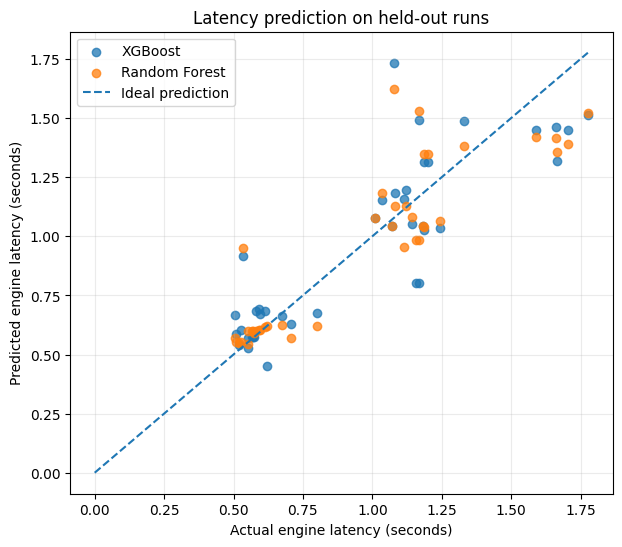

Test error by workload:


,requests,MAE_s,mean_actual_s,mean_predicted_s
workload_type,,,,
bursty,20,0.1269,1.0211,0.9797
steady,20,0.1235,0.9020,0.9208


In [53]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
for name, pred in test_predictions.items():
    ax.scatter(y_test, pred, alpha=0.75, label=name)
upper = max(float(y_test.max()), max(float(np.max(p)) for p in test_predictions.values()))
ax.plot([0, upper], [0, upper], linestyle="--", label="Ideal prediction")
ax.set_xlabel("Actual engine latency (seconds)")
ax.set_ylabel("Predicted engine latency (seconds)")
ax.set_title("Latency prediction on held-out runs")
ax.legend()
ax.grid(True, alpha=0.25)
plt.show()

selected_test_rows = df.loc[X_test.index, ["run_id", "workload_type"]].copy() if "workload_type" in df.columns else df.loc[X_test.index, ["run_id"]].copy()
selected_test_rows["actual_engine_latency_s"] = y_test.to_numpy()
selected_test_rows["predicted_engine_latency_s"] = selected_test_pred
selected_test_rows["calibrated_upper_latency_s"] = upper_test_pred
selected_test_rows["absolute_error_s"] = np.abs(y_test.to_numpy() - selected_test_pred)
print("Test error by workload:")
if "workload_type" in selected_test_rows.columns:
    display(selected_test_rows.groupby("workload_type").agg(
        requests=("actual_engine_latency_s", "count"),
        MAE_s=("absolute_error_s", "mean"),
        mean_actual_s=("actual_engine_latency_s", "mean"),
        mean_predicted_s=("predicted_engine_latency_s", "mean")
    ).round(4))
else:
    display(selected_test_rows.head())

## 11. Save trained models and experiment outputs

The files are written to `/content/camp_model_outputs/`. Download them or copy them to Google Drive before the Colab runtime ends. Notebook 03 will load the selected model and its metadata.

In [54]:
OUTPUT_DIR = Path("/content/camp_model_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save both comparison models and the selected model separately.
for name, fitted in fitted_models.items():
    safe_name = name.lower().replace(" ", "_")
    dump(fitted, OUTPUT_DIR / f"{safe_name}_latency_pipeline.joblib")

dump(selected_model, OUTPUT_DIR / "camp_latency_predictor.joblib")

# Save predictions for final analysis and reproducibility.
prediction_output = selected_test_rows.copy()
prediction_output.to_csv(OUTPUT_DIR / "predictor_test_predictions.csv", index=False)
cv_results.to_csv(OUTPUT_DIR / "predictor_group_cv_results.csv", index=False)
test_metrics.to_csv(OUTPUT_DIR / "predictor_test_metrics.csv", index=False)

metadata = {
    "project": "CAMP - Calibration-Aware ML-Predictive Scheduling",
    "target": TARGET,
    "target_definition": "completion_time - admission_time as recorded by Notebook 01; client-observed engine interval, not pure GPU compute time",
    "features": FEATURES,
    "selected_model": selected_name,
    "selected_model_file": "camp_latency_predictor.joblib",
    "calibration_method": "one-sided empirical 90th-percentile residual margin on run-held-out calibration partition",
    "calibration_residual_margin_s": residual_margin,
    "calibration_quantile_level": q_level,
    "calibration_rows": int(len(X_cal)),
    "test_coverage": empirical_test_coverage,
    "train_run_ids": sorted(train_groups),
    "calibration_run_ids": sorted(cal_groups),
    "test_run_ids": sorted(test_groups),
    "seed": SEED,
    "scikit_learn_version": sklearn.__version__,
    "xgboost_version": xgboost.__version__,
    "warning": "Pilot results only. Residual calibration is empirical, not a formal guarantee; validate on more independent workload runs and under distribution shift."
}
(OUTPUT_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))

print("Saved model and outputs in:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{path.name:45s} {path.stat().st_size/1024:8.1f} KB")

Saved model and outputs in: /content/camp_model_outputs
camp_latency_predictor.joblib                   1431.5 KB
model_metadata.json                                1.3 KB
predictor_group_cv_results.csv                     0.1 KB
predictor_test_metrics.csv                         0.2 KB
predictor_test_predictions.csv                     3.9 KB
random_forest_latency_pipeline.joblib           1431.5 KB
xgboost_latency_pipeline.joblib                  443.4 KB


## 12. Download the artifacts

Download the selected model, metadata, comparison metrics and test predictions. Keep the model and metadata together; Notebook 03 needs both.

In [55]:
from google.colab import files

for filename in [
    "camp_latency_predictor.joblib",
    "model_metadata.json",
    "predictor_test_metrics.csv",
    "predictor_group_cv_results.csv",
    "predictor_test_predictions.csv"
]:
    path = OUTPUT_DIR / filename
    if path.exists():
        files.download(str(path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Notebook 03 — Scheduler Experiments and Results

**Project:** CAMP — Calibration-Aware ML-Predictive Scheduling for Single-GPU LLM Inference  
**Backend:** Qwen2.5-1.5B-Instruct served by vLLM  
**GPU:** Google Colab Tesla T4 (or another compatible Colab GPU)

This notebook runs the **same benchmark requests** through four policies:

1. **FIFO:** forward requests to vLLM immediately in arrival order; vLLM manages its internal queue.
2. **Fixed-K:** an external FIFO queue with a fixed limit of `K=2` submitted requests.
3. **Heuristic Adaptive:** selects queued requests using prompt/output-token cost, waiting-time aging, and a shared adaptive concurrency controller.
4. **CAMP ML-Predictive:** uses the trained Random Forest latency predictor, its calibration residual margin, the same aging rule, and the same adaptive concurrency controller.

It prints generated responses and measured results, then saves CSV files and plots. **No dashboard or GUI is used.**

> **Important:** Notebook 01 currently creates a small pilot benchmark (12 requests per workload type). The results from this notebook are a pipeline demonstration, not publication-grade evidence. For a paper, increase trace size, use multiple independent trace seeds/repetitions, and repeat the full comparison under the same GPU/model configuration.

## 0. Files needed from Notebooks 01 and 02

Upload these four downloaded files when prompted:

- `benchmark_traces.csv` — independent test requests from Notebook 01
- `latency_dataset.csv` — measured request data from Notebook 01 (used to define and report a common pilot engine-latency SLO)
- `camp_latency_predictor.joblib` — selected trained predictor from Notebook 02
- `model_metadata.json` — predictor feature list and calibration margin from Notebook 02

The files must come from the **same run** of Notebooks 01 and 02. The model and metadata must match. Do not use the training latency dataset as the scheduler's benchmark trace.

In [56]:
# Install only lightweight client/analysis packages if needed.
# Do not reinstall vLLM or upgrade PyTorch in this notebook.
%pip -q install openai joblib pandas numpy matplotlib transformers scikit-learn==1.9.1

In [57]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GiB): 14.56


In [58]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [59]:
import asyncio
import json
import math
import os
import shutil
import subprocess
import threading
import time
import warnings
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sklearn
from joblib import load
from openai import AsyncOpenAI
from transformers import AutoTokenizer
from IPython.display import display

SEED = 42
np.random.seed(SEED)

print("Python:", os.sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("A CUDA GPU is required for the vLLM scheduler experiments. Select a GPU runtime in Colab.")
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

Python: 3.13.16
PyTorch: 2.14.1+cu130
scikit-learn: 1.9.1
CUDA available: True
GPU: Tesla T4
GPU memory (GiB): 14.56


In [60]:
# Search Colab storage and the project folder in mounted Google Drive.
from pathlib import Path
from google.colab import files

PROJECT_DIR = Path("/content")
SEARCH_DIRS = [Path("/content"), PROJECT_DIR]

REQUIRED_PATTERNS = {
    "benchmark": "benchmark_traces*.csv",
    "dataset": "latency_dataset*.csv",
    "model": "camp_latency_predictor*.joblib",
    "metadata": "model_metadata*.json",
}

def find_latest(pattern):
    matches = [
        path
        for directory in SEARCH_DIRS
        if directory.exists()
        for path in directory.glob(pattern)
        if path.is_file()
    ]
    return max(matches, key=lambda p: p.stat().st_mtime) if matches else None

missing = [name for name, pattern in REQUIRED_PATTERNS.items() if find_latest(pattern) is None]
if missing:
    print(f"Missing files: {missing}. Select those files from your computer to upload.")
    files.upload()

paths = {name: find_latest(pattern) for name, pattern in REQUIRED_PATTERNS.items()}
missing_after = [name for name, path in paths.items() if path is None]
if missing_after:
    raise FileNotFoundError(
        f"Still missing {missing_after}. Upload them to /content or "
        f"place them in {PROJECT_DIR}, then rerun this cell."
    )

for name, path in paths.items():
    print(f"{name:10s}: {path}")

Missing files: ['model', 'metadata']. Select those files from your computer to upload.


Saving camp_latency_predictor (1).joblib to camp_latency_predictor (1).joblib
Saving model_metadata (1).json to model_metadata (1).json
benchmark : /content/benchmark_traces_tokenfixed.csv
dataset   : /content/latency_dataset_tokenfixed.csv
model     : /content/camp_latency_predictor (1).joblib
metadata  : /content/model_metadata (1).json


In [61]:
# Load traces, collected data, model, and its metadata.
benchmark_df = pd.read_csv(paths["benchmark"])
latency_df = pd.read_csv(paths["dataset"])
model_metadata = json.loads(paths["metadata"].read_text())
predictor = load(paths["model"])

BENCHMARK_REQUIRED = {
    "request_id", "workload_type", "arrival_offset_s", "prompt_text",
    "prompt_tokens", "max_output_tokens"
}
missing_cols = BENCHMARK_REQUIRED - set(benchmark_df.columns)
if missing_cols:
    raise ValueError(f"benchmark_traces.csv is missing columns: {sorted(missing_cols)}")

if "engine_latency_s" not in latency_df or "status" not in latency_df:
    raise ValueError("latency_dataset.csv must contain engine_latency_s and status columns.")

FEATURES = model_metadata.get("features", [])
if not FEATURES:
    raise ValueError("model_metadata.json has no predictor feature list.")
CALIBRATION_MARGIN_S = float(model_metadata.get("calibration_residual_margin_s", 0.0))
SELECTED_MODEL_NAME = model_metadata.get("selected_model", "Unknown model")

print("Predictor selected in Notebook 02:", SELECTED_MODEL_NAME)
print("Predictor features:", FEATURES)
print("Calibration residual margin (s):", round(CALIBRATION_MARGIN_S, 4))
print("Benchmark shape:", benchmark_df.shape)
print("Training-data shape:", latency_df.shape)
display(benchmark_df.groupby("workload_type").agg(
    requests=("request_id", "count"),
    mean_prompt_tokens=("prompt_tokens", "mean"),
    mean_max_output_tokens=("max_output_tokens", "mean")
).round(2))

# Check for a likely model/package version mismatch before loading predictions.
trained_sklearn = model_metadata.get("scikit_learn_version")
if trained_sklearn and trained_sklearn != sklearn.__version__:
    warnings.warn(
        f"The predictor was trained with scikit-learn {trained_sklearn}, "
        f"but this runtime has {sklearn.__version__}. Joblib/sklearn compatibility can vary. "
        "If prediction fails, use the same scikit-learn version as Notebook 02."
    )

Predictor selected in Notebook 02: Random Forest
Predictor features: ['prompt_tokens', 'max_output_tokens', 'arrival_rate_5s_rps', 'queue_depth_at_admission', 'active_requests_at_admission', 'concurrency_limit', 'gpu_utilization_pct', 'gpu_memory_used_mib']
Calibration residual margin (s): 0.2789
Benchmark shape: (36, 6)
Training-data shape: (180, 21)


,requests,mean_prompt_tokens,mean_max_output_tokens
workload_type,,,
bursty,12,350.33,74.67
mixed,12,179.17,72.00
steady,12,310.25,66.67


In [62]:
client = AsyncOpenAI(base_url=BASE_URL, api_key="EMPTY", timeout=600.0, max_retries=0)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)

# AsyncOpenAI model listing must be awaited in Colab.
model_list = await client.models.list()
available_model_ids = [item.id for item in model_list.data]
print("Available model IDs:", available_model_ids)
if MODEL_ID not in available_model_ids:
    raise RuntimeError(f"Expected model {MODEL_ID} is not exposed by vLLM. Check server logs.")

# Warm-up request: excluded from all benchmark measurements.
warmup = await client.chat.completions.create(
    model=MODEL_ID,
    messages=[{"role": "user", "content": "Reply with the word READY."}],
    max_tokens=8,
    temperature=0
)
print("Warm-up response:", warmup.choices[0].message.content)

Available model IDs: ['Qwen/Qwen2.5-1.5B-Instruct']
Warm-up response: READY


In [63]:
# CAMP: Correct prompt-token counting

def exact_prompt_token_count(text):
    messages = [
        {"role": "user", "content": str(text)}
    ]

    token_ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=False
    )

    return len(token_ids)


# Correct training dataset
latency_df["prompt_tokens"] = (
    latency_df["prompt_text"].apply(exact_prompt_token_count)
)

# Correct benchmark dataset
benchmark_df["prompt_tokens"] = (
    benchmark_df["prompt_text"].apply(exact_prompt_token_count)
)

print("TRAINING TOKEN DISTRIBUTION")
display(latency_df["prompt_tokens"].describe())

print("\nBENCHMARK TOKEN DISTRIBUTION")
display(benchmark_df["prompt_tokens"].describe())

print("\nWORKLOAD-WISE DISTRIBUTION")
display(
    benchmark_df.groupby("workload_type")["prompt_tokens"].describe()
)

assert latency_df["prompt_tokens"].nunique() >= 3
assert benchmark_df["prompt_tokens"].nunique() >= 3

print("\nSUCCESS: Token counts corrected!")

TRAINING TOKEN DISTRIBUTION


,prompt_tokens
count,180.000000
mean,250.022222
std,178.175670
min,49.000000
25%,144.000000
50%,272.500000
75%,273.000000
max,529.000000



BENCHMARK TOKEN DISTRIBUTION


,prompt_tokens
count,36.000000
mean,279.916667
std,194.179059
min,48.000000
25%,144.750000
50%,273.000000
75%,529.000000
max,529.000000



WORKLOAD-WISE DISTRIBUTION


,count,mean,std,min,25%,50%,75%,max
workload_type,,,,,,,,
bursty,12.0,350.333333,195.582735,49.0,145.00,401.0,529.0,529.0
mixed,12.0,179.166667,149.475953,48.0,48.00,145.0,273.0,529.0
steady,12.0,310.250000,204.670522,49.0,144.75,273.0,529.0,529.0



SUCCESS: Token counts corrected!


In [43]:
latency_df.to_csv(
    "/content/latency_dataset_tokenfixed.csv",
    index=False
)

benchmark_df.to_csv(
    "/content/benchmark_traces_tokenfixed.csv",
    index=False
)

from google.colab import files

files.download("/content/latency_dataset_tokenfixed.csv")
files.download("/content/benchmark_traces_tokenfixed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 2. Common experiment settings

All four policies use the same prompts, requested output limits, arrival offsets, Qwen model, vLLM server, and GPU. The fixed baseline uses `K=2`; adaptive policies begin at `K=2` and may adjust between 1 and 4. The vLLM backend is configured with `max-num-seqs=4`.

The engine-latency SLO below is defined from the **90th percentile of successful Notebook 01 pilot measurements**. This is a transparent pilot threshold, not an externally supplied production SLO. Report its value in any paper or presentation.

In [64]:
FIXED_K = 2
MIN_ADAPTIVE_K = 1
INITIAL_ADAPTIVE_K = 2
MAX_ADAPTIVE_K = 4
AGING_TAU_S = 5.0
MAX_WAIT_PRIORITY_S = 15.0
HEURISTIC_OUTPUT_WEIGHT = 1.0

successful_training = latency_df[
    latency_df["status"].astype(str).str.lower().eq("completed")
].copy()
successful_training["engine_latency_s"] = pd.to_numeric(
    successful_training["engine_latency_s"], errors="coerce"
)
successful_training = successful_training[
    np.isfinite(successful_training["engine_latency_s"])
    & (successful_training["engine_latency_s"] > 0)
]
if len(successful_training) < 5:
    raise ValueError("Too few successful collection rows to define the pilot SLO.")

SLO_TARGET_S = float(successful_training["engine_latency_s"].quantile(0.90))
print("Fixed-K:", FIXED_K)
print("Adaptive concurrency range:", MIN_ADAPTIVE_K, "to", MAX_ADAPTIVE_K)
print("Aging tau (s):", AGING_TAU_S)
print("Pilot engine-latency SLO (90th percentile, seconds):", round(SLO_TARGET_S, 4))
print("Benchmark requests:", len(benchmark_df))
print("Workloads:", sorted(benchmark_df["workload_type"].astype(str).unique()))

if len(benchmark_df) < 100:
    warnings.warn(
        "This benchmark trace has fewer than 100 requests. Treat policy comparisons as a pilot; "
        "do not claim statistically reliable improvements from this run."
    )

Fixed-K: 2
Adaptive concurrency range: 1 to 4
Aging tau (s): 5.0
Pilot engine-latency SLO (90th percentile, seconds): 1.5878
Benchmark requests: 36
Workloads: ['bursty', 'mixed', 'steady']


/tmp/ipykernel_571/415200926.py:31: UserWarning: This benchmark trace has fewer than 100 requests. Treat policy comparisons as a pilot; do not claim statistically reliable improvements from this run.
  warnings.warn(


In [65]:
# Background GPU telemetry sampler. Samples are read at request-admission decisions.
_gpu_stop = threading.Event()
_gpu_lock = threading.Lock()
_gpu_samples = []

def _sample_gpu_loop():
    while not _gpu_stop.is_set():
        try:
            output = subprocess.check_output(
                ["nvidia-smi", "--query-gpu=utilization.gpu,memory.used,memory.total",
                 "--format=csv,noheader,nounits"],
                text=True, stderr=subprocess.DEVNULL, timeout=5
            )
            fields = [x.strip() for x in output.strip().split(",")]
            sample = {
                "gpu_utilization_pct": float(fields[0]),
                "gpu_memory_used_mib": float(fields[1]),
                "gpu_memory_total_mib": float(fields[2]),
                "sampled_at": time.perf_counter()
            }
            with _gpu_lock:
                _gpu_samples.append(sample)
                if len(_gpu_samples) > 5000:
                    del _gpu_samples[:1000]
        except Exception:
            pass
        _gpu_stop.wait(1.0)

_gpu_thread = threading.Thread(target=_sample_gpu_loop, daemon=True)
_gpu_thread.start()
time.sleep(2)

def latest_gpu_sample():
    with _gpu_lock:
        if _gpu_samples:
            return dict(_gpu_samples[-1])
    return {
        "gpu_utilization_pct": np.nan,
        "gpu_memory_used_mib": np.nan,
        "gpu_memory_total_mib": np.nan,
        "sampled_at": np.nan
    }

print("Initial GPU telemetry:", latest_gpu_sample())

Initial GPU telemetry: {'sampled_at_perf': 3095.834421874, 'gpu_utilization_pct': 0.0, 'gpu_memory_used_mib': 12535.0, 'gpu_memory_total_mib': 15360.0}


## 3. Request execution and feature construction

The predictor receives only information available at the admission decision. The target it predicts is the same target used in Notebook 02: time from external submission to final streamed response (`engine_latency_s`). It is an endpoint-observed engine interval, not a measurement of pure GPU compute time.

In [66]:
def arrival_rate_5s(arrival_times, now, run_start):
    recent_count = sum(t >= now - 5.0 for t in arrival_times)
    window = min(5.0, max(0.2, now - run_start))
    return float(recent_count / window)


def build_predictor_features(spec, queue_depth, active_requests, concurrency_limit,
                             arrival_times, now, run_start, gpu):
    values = {
        "prompt_tokens": float(spec["prompt_tokens"]),
        "max_output_tokens": float(spec["max_output_tokens"]),
        "arrival_rate_5s_rps": arrival_rate_5s(arrival_times, now, run_start),
        "queue_depth_at_admission": float(queue_depth),
        "active_requests_at_admission": float(active_requests),
        "concurrency_limit": float(concurrency_limit),
        "gpu_utilization_pct": gpu.get("gpu_utilization_pct", np.nan),
        "gpu_memory_used_mib": gpu.get("gpu_memory_used_mib", np.nan),
    }
    # Use precisely the feature names/order recorded with the trained pipeline.
    return pd.DataFrame([[values.get(name, np.nan) for name in FEATURES]], columns=FEATURES)


def predict_latency_and_upper(feature_frame):
    prediction = float(np.asarray(predictor.predict(feature_frame)).reshape(-1)[0])
    prediction = max(0.0, prediction)
    upper = prediction + max(0.0, CALIBRATION_MARGIN_S)
    return prediction, upper


async def execute_request(spec, enqueue_at, run_start, arrival_times, state,
                          queue_depth, concurrency_limit, policy_name,
                          predicted_latency=np.nan, calibrated_upper=np.nan,
                          predictor_fallback=False):
    admission_at = time.perf_counter()
    active_at_admission = state["active"]
    state["active"] += 1
    gpu = latest_gpu_sample()
    feature_frame = build_predictor_features(
        spec, queue_depth, active_at_admission, concurrency_limit,
        arrival_times, admission_at, run_start, gpu
    )
    output_text = ""
    first_token_at = None
    status = "completed"
    error = ""
    completion_at = admission_at

    try:
        stream = await client.chat.completions.create(
            model=MODEL_ID,
            messages=[{"role": "user", "content": str(spec["prompt_text"])}],
            max_tokens=int(spec["max_output_tokens"]),
            temperature=0,
            stream=True
        )
        async for chunk in stream:
            if not chunk.choices:
                continue
            piece = chunk.choices[0].delta.content
            if piece:
                if first_token_at is None:
                    first_token_at = time.perf_counter()
                output_text += piece
        completion_at = time.perf_counter()
    except Exception as exc:
        completion_at = time.perf_counter()
        status = "failed"
        error = f"{type(exc).__name__}: {str(exc)[:250]}"
    finally:
        state["active"] = max(0, state["active"] - 1)

    output_tokens = len(tokenizer.encode(output_text, add_special_tokens=False)) if output_text else 0
    return {
        "request_id": spec["request_id"],
        "workload_type": spec["workload_type"],
        "policy": policy_name,
        "arrival_offset_s": float(spec["arrival_offset_s"]),
        "prompt_tokens": int(spec["prompt_tokens"]),
        "max_output_tokens": int(spec["max_output_tokens"]),
        "actual_output_tokens": int(output_tokens),
        "queue_wait_s": max(0.0, admission_at - enqueue_at),
        "engine_latency_s": max(0.0, completion_at - admission_at),
        "end_to_end_s": max(0.0, completion_at - enqueue_at),
        "ttft_engine_s": (first_token_at - admission_at) if first_token_at else np.nan,
        "arrival_rate_5s_rps": arrival_rate_5s(arrival_times, admission_at, run_start),
        "queue_depth_at_admission": int(queue_depth),
        "active_requests_at_admission": int(active_at_admission),
        "concurrency_limit_at_admission": int(concurrency_limit),
        "gpu_utilization_pct": gpu.get("gpu_utilization_pct", np.nan),
        "gpu_memory_used_mib": gpu.get("gpu_memory_used_mib", np.nan),
        "predicted_engine_latency_s": predicted_latency,
        "calibrated_upper_latency_s": calibrated_upper,
        "predictor_fallback": bool(predictor_fallback),
        "status": status,
        "error": error,
        "output_preview": output_text[:240],
        "enqueue_perf": enqueue_at,
        "completion_perf": completion_at,
    }

## 4. Implement the four scheduling policies

- **FIFO:** requests are submitted to vLLM as they arrive; the backend manages its own queue.
- **Fixed-K:** a FIFO queue is drained by exactly `K=2` external workers.
- **Heuristic Adaptive:** queued requests are ranked by `prompt_tokens + output_weight × max_output_tokens`, with aging.
- **CAMP:** queued requests are ranked by the calibrated upper latency estimate (`prediction + calibration residual margin`), with the same aging rule.

The two adaptive policies share the same concurrency controller. It adjusts the external limit from recent measured engine latency and GPU memory telemetry. This keeps the main comparison focused on the **heuristic size estimate versus the calibrated ML estimate**.

In [67]:
async def wait_until(start_time, offset_s):
    delay = start_time + float(offset_s) - time.perf_counter()
    if delay > 0:
        await asyncio.sleep(delay)


def records_for_workload(workload_type):
    part = benchmark_df[benchmark_df["workload_type"].astype(str).eq(str(workload_type))].copy()
    part = part.sort_values(["arrival_offset_s", "request_id"]).reset_index(drop=True)
    if part.empty:
        raise ValueError(f"No requests found for workload {workload_type}")
    return part.to_dict("records")


async def run_fifo(specs, workload_type):
    run_start = time.perf_counter()
    arrival_times = []
    state = {"active": 0}
    tasks = []

    async def producer():
        for spec in specs:
            await wait_until(run_start, spec["arrival_offset_s"])
            enqueue_at = time.perf_counter()
            arrival_times.append(enqueue_at)
            # Immediate dispatch in arrival order; vLLM manages its internal queue.
            tasks.append(asyncio.create_task(execute_request(
                spec, enqueue_at, run_start, arrival_times, state,
                queue_depth=0, concurrency_limit=MAX_ADAPTIVE_K,
                policy_name="FIFO"
            )))

    await producer()
    results = await asyncio.gather(*tasks)
    return results


async def run_fixed_k(specs, workload_type):
    run_start = time.perf_counter()
    arrival_times = []
    state = {"active": 0}
    queue = asyncio.Queue()
    results = []

    async def producer():
        for spec in specs:
            await wait_until(run_start, spec["arrival_offset_s"])
            enqueue_at = time.perf_counter()
            arrival_times.append(enqueue_at)
            await queue.put((spec, enqueue_at))
        for _ in range(FIXED_K):
            await queue.put(None)

    async def worker():
        while True:
            item = await queue.get()
            if item is None:
                queue.task_done()
                return
            spec, enqueue_at = item
            result = await execute_request(
                spec, enqueue_at, run_start, arrival_times, state,
                queue_depth=queue.qsize(), concurrency_limit=FIXED_K,
                policy_name="Fixed-K"
            )
            results.append(result)
            queue.task_done()

    workers = [asyncio.create_task(worker()) for _ in range(FIXED_K)]
    producer_task = asyncio.create_task(producer())
    await producer_task
    await queue.join()
    await asyncio.gather(*workers)
    return results


def age_adjusted_priority(cost, wait_s):
    # After the maximum-wait threshold, explicitly elevate the request.
    if wait_s >= MAX_WAIT_PRIORITY_S:
        return -1_000_000.0 - wait_s
    return float(cost) / (1.0 + max(0.0, wait_s) / AGING_TAU_S)


def update_adaptive_limit(current_limit, completed_engine_latencies):
    # Shared controller for both adaptive policies; evaluated every 3 completions.
    if len(completed_engine_latencies) < 3 or len(completed_engine_latencies) % 3 != 0:
        return current_limit
    recent = np.asarray(completed_engine_latencies[-5:], dtype=float)
    recent_p75 = float(np.quantile(recent, 0.75))
    gpu = latest_gpu_sample()
    memory_ratio = (
        gpu["gpu_memory_used_mib"] / gpu["gpu_memory_total_mib"]
        if np.isfinite(gpu["gpu_memory_used_mib"]) and gpu["gpu_memory_total_mib"] > 0
        else 0.0
    )
    if recent_p75 > 1.05 * SLO_TARGET_S or memory_ratio > 0.92:
        return max(MIN_ADAPTIVE_K, current_limit - 1)
    if recent_p75 < 0.75 * SLO_TARGET_S and memory_ratio < 0.85:
        return min(MAX_ADAPTIVE_K, current_limit + 1)
    return current_limit


async def run_adaptive(specs, workload_type, use_predictor):
    policy_name = "CAMP ML-Predictive" if use_predictor else "Heuristic Adaptive"
    run_start = time.perf_counter()
    arrival_times = []
    pending = []
    completed_results = []
    active_tasks = set()
    state = {"active": 0}
    effective_limit = INITIAL_ADAPTIVE_K
    done_producing = False

    async def producer():
        nonlocal done_producing
        for spec in specs:
            await wait_until(run_start, spec["arrival_offset_s"])
            enqueue_at = time.perf_counter()
            arrival_times.append(enqueue_at)
            pending.append({"spec": spec, "enqueue_at": enqueue_at})
        done_producing = True

    producer_task = asyncio.create_task(producer())
    recent_engine_latencies = []

    while (not done_producing) or pending or active_tasks:
        # Fill free external slots using the chosen policy's priority.
        while pending and len(active_tasks) < effective_limit:
            now = time.perf_counter()
            gpu = latest_gpu_sample()
            scored = []
            for item in pending:
                spec = item["spec"]
                wait_s = now - item["enqueue_at"]
                if use_predictor:
                    feature_frame = build_predictor_features(
                        spec, queue_depth=len(pending), active_requests=len(active_tasks),
                        concurrency_limit=effective_limit, arrival_times=arrival_times,
                        now=now, run_start=run_start, gpu=gpu
                    )
                    try:
                        pred, upper = predict_latency_and_upper(feature_frame)
                        item["predicted_engine_latency_s"] = pred
                        item["calibrated_upper_latency_s"] = upper
                        item["predictor_fallback"] = False
                    except Exception as exc:
                        # Conservative, explicit fallback to the heuristic estimate.
                        fallback_cost = float(spec["prompt_tokens"]) + HEURISTIC_OUTPUT_WEIGHT * float(spec["max_output_tokens"])
                        item["predicted_engine_latency_s"] = np.nan
                        item["calibrated_upper_latency_s"] = np.nan
                        item["predictor_fallback"] = True
                    if item["predictor_fallback"]:
                        cost = fallback_cost
                    else:
                        cost = item["calibrated_upper_latency_s"]
                else:
                    cost = float(spec["prompt_tokens"]) + HEURISTIC_OUTPUT_WEIGHT * float(spec["max_output_tokens"])
                    item["predicted_engine_latency_s"] = np.nan
                    item["calibrated_upper_latency_s"] = np.nan
                    item["predictor_fallback"] = False
                scored.append(age_adjusted_priority(cost, wait_s))

            chosen_index = int(np.argmin(scored))
            item = pending.pop(chosen_index)
            spec = item["spec"]
            task = asyncio.create_task(execute_request(
                spec, item["enqueue_at"], run_start, arrival_times, state,
                queue_depth=len(pending), concurrency_limit=effective_limit,
                policy_name=policy_name,
                predicted_latency=item.get("predicted_engine_latency_s", np.nan),
                calibrated_upper=item.get("calibrated_upper_latency_s", np.nan),
                predictor_fallback=item.get("predictor_fallback", False)
            ))
            active_tasks.add(task)

        if active_tasks:
            done, still_running = await asyncio.wait(
                active_tasks, timeout=0.05, return_when=asyncio.FIRST_COMPLETED
            )
            active_tasks = set(still_running)
            for task in done:
                result = task.result()
                completed_results.append(result)
                if result["status"] == "completed":
                    recent_engine_latencies.append(float(result["engine_latency_s"]))
                    effective_limit = update_adaptive_limit(effective_limit, recent_engine_latencies)
        else:
            await asyncio.sleep(0.01)

    await producer_task
    return completed_results

print("Four policy implementations are ready.")

Four policy implementations are ready.


## 5. Run the controlled comparison

The same per-workload trace is replayed for each policy. Policy order is rotated between workload types to reduce systematic order effects. Each run drains all submitted requests before the next policy starts.

In [68]:
POLICY_RUNNERS = [
    ("FIFO", run_fifo),
    ("Fixed-K", run_fixed_k),
    ("Heuristic Adaptive", lambda specs, workload: run_adaptive(specs, workload, use_predictor=False)),
    ("CAMP ML-Predictive", lambda specs, workload: run_adaptive(specs, workload, use_predictor=True)),
]

all_result_rows = []
workload_types = sorted(benchmark_df["workload_type"].astype(str).unique())

for workload_index, workload_type in enumerate(workload_types):
    specs = records_for_workload(workload_type)
    # Rotate order for each workload type; requests and settings remain identical.
    order = POLICY_RUNNERS[workload_index:] + POLICY_RUNNERS[:workload_index]
    print(f"\n{'='*72}\nWORKLOAD: {workload_type} | REQUESTS: {len(specs)}\n{'='*72}")
    for policy_name, runner in order:
        print(f"Running {policy_name} ...", end=" ", flush=True)
        start_wall = time.perf_counter()
        result_rows = await runner(specs, workload_type)
        elapsed_wall = time.perf_counter() - start_wall
        all_result_rows.extend(result_rows)
        successes = sum(row["status"] == "completed" for row in result_rows)
        print(f"done — {successes}/{len(result_rows)} completed in {elapsed_wall:.1f}s")
        await asyncio.sleep(2.0)  # short cooldown between policy runs

results_df = pd.DataFrame(all_result_rows)
if results_df.empty:
    raise RuntimeError("No scheduler results were produced.")
print("\nTotal request-policy observations:", len(results_df))
display(results_df.groupby(["workload_type", "policy", "status"]).size().rename("count").to_frame())


WORKLOAD: bursty | REQUESTS: 12
Running FIFO ... done — 12/12 completed in 7.6s
Running Fixed-K ... done — 12/12 completed in 8.0s
Running Heuristic Adaptive ... done — 12/12 completed in 7.7s
Running CAMP ML-Predictive ... done — 12/12 completed in 9.8s

WORKLOAD: mixed | REQUESTS: 12
Running Fixed-K ... done — 12/12 completed in 6.9s
Running Heuristic Adaptive ... done — 12/12 completed in 5.5s
Running CAMP ML-Predictive ... done — 12/12 completed in 9.4s
Running FIFO ... done — 12/12 completed in 5.2s

WORKLOAD: steady | REQUESTS: 12
Running Heuristic Adaptive ... done — 12/12 completed in 7.2s
Running CAMP ML-Predictive ... done — 12/12 completed in 8.1s
Running FIFO ... done — 12/12 completed in 7.2s
Running Fixed-K ... done — 12/12 completed in 7.2s

Total request-policy observations: 144


count
workload_type policy             status          
bursty        CAMP ML-Predictive completed     12
              FIFO               completed     12
              Fixed-K            completed     12
              Heuristic Adaptive completed     12
mixed         CAMP ML-Predictive completed     12
              FIFO               completed     12
              Fixed-K            completed     12
              Heuristic Adaptive completed     12
steady        CAMP ML-Predictive completed     12
              FIFO               completed     12
              Fixed-K            completed     12
              Heuristic Adaptive completed     12

## 6. Calculate metrics

Metric boundaries match the definitions used in Notebook 01 and the literature review:

- `queue_wait_s`: external waiting time before the request is sent to vLLM.
- `engine_latency_s`: request submission to final streamed response; includes vLLM-side queueing, prefill, decode, and response streaming.
- `end_to_end_s`: external queue entry to final streamed response.
- `goodput`: requests completing within the shared pilot engine-latency SLO, divided by experiment duration.

Failed requests are counted separately and are not silently dropped from the success-rate calculation.

In [69]:
def safe_quantile(series, q):
    values = pd.to_numeric(series, errors="coerce").dropna()
    return float(values.quantile(q)) if len(values) else np.nan

summary_rows = []
for (workload, policy), group in results_df.groupby(["workload_type", "policy"], sort=False):
    successful = group[group["status"].eq("completed")].copy()
    submitted = len(group)
    completed = len(successful)
    failed = submitted - completed
    start_perf = float(group["enqueue_perf"].min())
    finish_perf = float(group["completion_perf"].max())
    duration_s = max(1e-9, finish_perf - start_perf)
    on_time = int((successful["engine_latency_s"] <= SLO_TARGET_S).sum()) if completed else 0

    summary_rows.append({
        "workload_type": workload,
        "policy": policy,
        "submitted": submitted,
        "completed": completed,
        "failed": failed,
        "success_rate": completed / submitted if submitted else np.nan,
        "duration_s": duration_s,
        "mean_queue_wait_s": successful["queue_wait_s"].mean() if completed else np.nan,
        "p95_queue_wait_s": safe_quantile(successful["queue_wait_s"], 0.95),
        "max_queue_wait_s": successful["queue_wait_s"].max() if completed else np.nan,
        "mean_engine_latency_s": successful["engine_latency_s"].mean() if completed else np.nan,
        "p50_engine_latency_s": safe_quantile(successful["engine_latency_s"], 0.50),
        "p95_engine_latency_s": safe_quantile(successful["engine_latency_s"], 0.95),
        "p99_engine_latency_s": safe_quantile(successful["engine_latency_s"], 0.99),
        "p95_end_to_end_s": safe_quantile(successful["end_to_end_s"], 0.95),
        "p50_ttft_engine_s": safe_quantile(successful["ttft_engine_s"], 0.50),
        "request_throughput_rps": completed / duration_s,
        "output_token_throughput_tps": successful["actual_output_tokens"].sum() / duration_s if completed else 0.0,
        "goodput_rps": on_time / duration_s,
        "engine_slo_target_s": SLO_TARGET_S,
        "mean_gpu_utilization_pct": successful["gpu_utilization_pct"].mean() if completed else np.nan,
        "max_gpu_memory_used_mib": successful["gpu_memory_used_mib"].max() if completed else np.nan,
        "predictor_fallback_count": int(group["predictor_fallback"].sum()),
    })

summary_df = pd.DataFrame(summary_rows)
print("Scheduler summary (times in seconds; throughput in requests/tokens per second):")
display(summary_df.sort_values(["workload_type", "policy"]).round(4))

Scheduler summary (times in seconds; throughput in requests/tokens per second):


,workload_type,policy,submitted,completed,failed,success_rate,duration_s,mean_queue_wait_s,p95_queue_wait_s,max_queue_wait_s,...,p99_engine_latency_s,p95_end_to_end_s,p50_ttft_engine_s,request_throughput_rps,output_token_throughput_tps,goodput_rps,engine_slo_target_s,mean_gpu_utilization_pct,max_gpu_memory_used_mib,predictor_fallback_count
3,bursty,CAMP ML-Predictive,12,12,0,1.0,9.7837,1.6286,3.2286,3.6102,...,1.9749,4.8792,0.0700,1.2265,83.6087,1.1243,1.5878,72.3333,12535.0,0
0,bursty,FIFO,12,12,0,1.0,7.6038,0.0001,0.0001,0.0001,...,1.7458,1.7079,0.0791,1.5781,107.1826,1.3151,1.5878,0.0000,12535.0,0
1,bursty,Fixed-K,12,12,0,1.0,8.0190,0.7898,2.0344,2.0374,...,1.6906,3.1785,0.0736,1.4964,102.0071,1.1223,1.5878,83.2500,12535.0,0
2,bursty,Heuristic Adaptive,12,12,0,1.0,7.6666,0.5378,1.5224,1.5791,...,1.6456,2.6196,0.0750,1.5652,106.6962,1.4348,1.5878,69.8333,12535.0,0
6,mixed,CAMP ML-Predictive,12,12,0,1.0,9.3704,1.9739,3.9077,4.2855,...,1.7335,5.2283,0.0786,1.2806,86.2294,1.0672,1.5878,51.3333,12535.0,0
7,mixed,FIFO,12,12,0,1.0,5.1808,0.0000,0.0001,0.0001,...,1.5936,1.5697,0.0596,2.3163,155.9614,2.1232,1.5878,84.6667,12535.0,0
4,mixed,Fixed-K,12,12,0,1.0,6.9096,0.8637,1.8810,1.9307,...,1.5345,2.9876,0.0500,1.7367,116.9380,1.7367,1.5878,83.9167,12535.0,0
5,mixed,Heuristic Adaptive,12,12,0,1.0,5.4717,0.4397,1.1822,1.3932,...,1.6114,2.0383,0.0835,2.1931,147.6690,2.0103,1.5878,80.1667,12535.0,0
9,steady,CAMP ML-Predictive,12,12,0,1.0,8.1223,0.4187,0.8628,0.8886,...,1.7906,2.0968,0.0793,1.4774,88.1519,1.3543,1.5878,76.3333,12535.0,0
10,steady,FIFO,12,12,0,1.0,7.1852,0.0001,0.0001,0.0001,...,1.5708,1.4453,0.0612,1.6701,99.6494,1.5309,1.5878,91.5833,12535.0,0


In [70]:
# Evaluate CAMP's point and calibrated-upper predictions against actual engine latency.
camp_rows = results_df[
    results_df["policy"].eq("CAMP ML-Predictive")
    & results_df["status"].eq("completed")
    & results_df["predicted_engine_latency_s"].notna()
].copy()

if len(camp_rows):
    actual = camp_rows["engine_latency_s"].to_numpy(dtype=float)
    point = camp_rows["predicted_engine_latency_s"].to_numpy(dtype=float)
    upper = camp_rows["calibrated_upper_latency_s"].to_numpy(dtype=float)
    predictor_report = pd.DataFrame([{
        "requests": len(camp_rows),
        "MAE_s": float(np.mean(np.abs(actual - point))),
        "RMSE_s": float(np.sqrt(np.mean((actual - point) ** 2))),
        "underprediction_rate": float(np.mean(actual > point)),
        "calibrated_upper_coverage": float(np.mean(actual <= upper)),
        "fallback_count": int(results_df.loc[
            results_df["policy"].eq("CAMP ML-Predictive"), "predictor_fallback"
        ].sum()),
    }])
    print("CAMP prediction quality on scheduler benchmark requests:")
    display(predictor_report.round(4))
else:
    predictor_report = pd.DataFrame()
    print("No valid CAMP predictions were available. Inspect predictor features and fallback counts.")

print("\nFirst response examples (up to one per policy/workload):")
examples = (results_df[results_df["status"].eq("completed")]
            .sort_values("completion_perf")
            .groupby(["workload_type", "policy"], as_index=False)
            .head(1))
for _, row in examples.iterrows():
    print(f"\n[{row['workload_type']} | {row['policy']} | {row['request_id']}]")
    print(row["output_preview"] or "<empty response>")

CAMP prediction quality on scheduler benchmark requests:


,requests,MAE_s,RMSE_s,underprediction_rate,calibrated_upper_coverage,fallback_count
0,36,0.2181,0.2868,0.6111,0.8056,0



First response examples (up to one per policy/workload):

[bursty | FIFO | benchmark_bursty_req_0003]
The given text describes various components in an AI system's request handling process, including:

1. **Prefill Phase**: Processes input tokens.
2. **Decode

[bursty | Fixed-K | benchmark_bursty_req_0000]
Large language models in serving systems experience increased latency due to bursts of requests that fill up the queue. This affects subsequent requests negatively. Key metrics like throughput (requests per second), tail latency (latency at

[bursty | Heuristic Adaptive | benchmark_bursty_req_0000]
Large language models in serving systems experience increased latency due to bursts of requests that fill up the queue. This affects subsequent requests negatively. Key metrics like throughput (requests per second), tail latency (latency at

[bursty | CAMP ML-Predictive | benchmark_bursty_req_0003]
The given text describes various components in an AI system's request handling process, inc

## 7. Compare policies and create plots

Interpret the results together: a policy that reduces p95 latency by rejecting or failing requests is not automatically better. Always inspect completion rate, goodput, output-token throughput, and queue waiting time alongside latency.

,workload_type,policy,success_rate,mean_queue_wait_s,p95_engine_latency_s,request_throughput_rps,output_token_throughput_tps,goodput_rps,max_queue_wait_s
3,bursty,CAMP ML-Predictive,1.0,1.6286,1.7645,1.2265,83.6087,1.1243,3.6102
0,bursty,FIFO,1.0,0.0001,1.7079,1.5781,107.1826,1.3151,0.0001
1,bursty,Fixed-K,1.0,0.7898,1.6462,1.4964,102.0071,1.1223,2.0374
2,bursty,Heuristic Adaptive,1.0,0.5378,1.6124,1.5652,106.6962,1.4348,1.5791
6,mixed,CAMP ML-Predictive,1.0,1.9739,1.7198,1.2806,86.2294,1.0672,4.2855
7,mixed,FIFO,1.0,0.0000,1.5697,2.3163,155.9614,2.1232,0.0001
4,mixed,Fixed-K,1.0,0.8637,1.5296,1.7367,116.9380,1.7367,1.9307
5,mixed,Heuristic Adaptive,1.0,0.4397,1.5824,2.1931,147.6690,2.0103,1.3932
9,steady,CAMP ML-Predictive,1.0,0.4187,1.5598,1.4774,88.1519,1.3543,0.8886
10,steady,FIFO,1.0,0.0001,1.4452,1.6701,99.6494,1.5309,0.0001


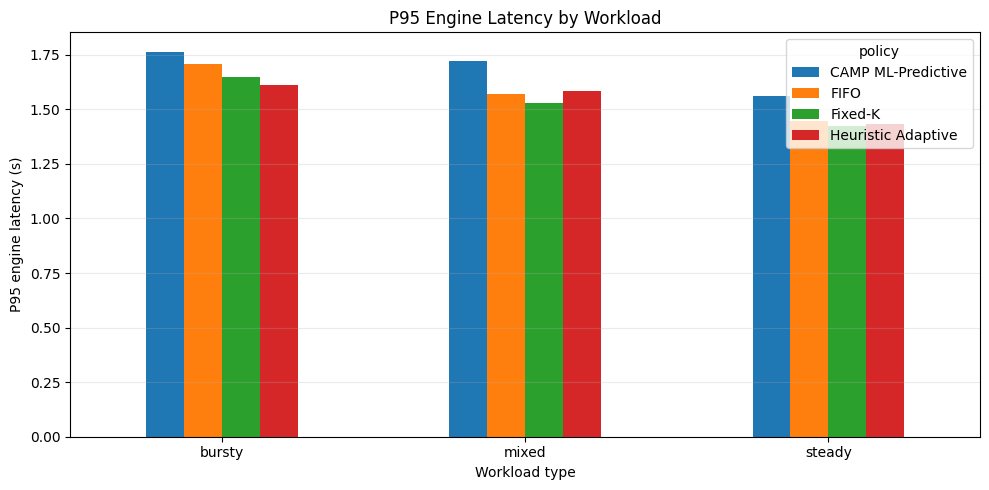

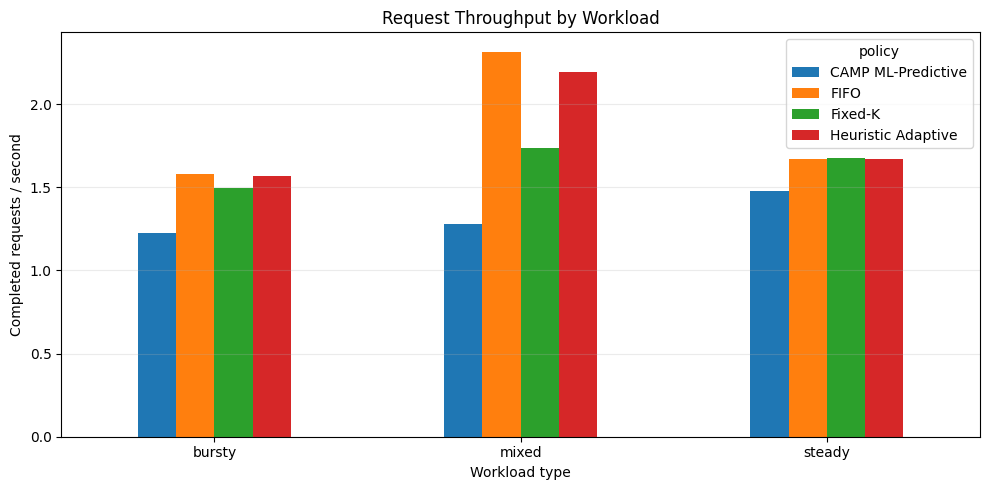

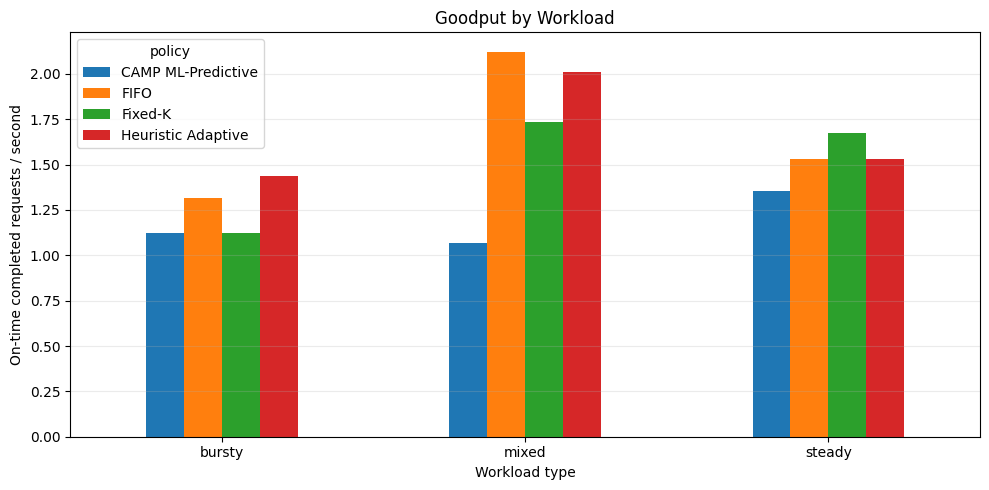

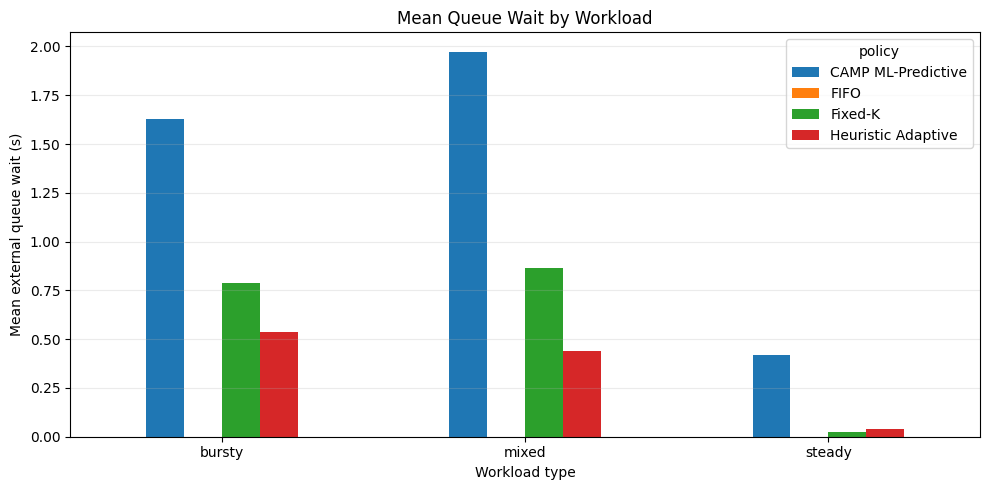

In [71]:
# Compact side-by-side comparison by workload.
comparison_columns = [
    "workload_type", "policy", "success_rate", "mean_queue_wait_s",
    "p95_engine_latency_s", "request_throughput_rps",
    "output_token_throughput_tps", "goodput_rps", "max_queue_wait_s"
]
comparison_df = summary_df[comparison_columns].copy()
display(comparison_df.sort_values(["workload_type", "policy"]).round(4))

# Plot p95 engine latency by workload and policy.
for metric, ylabel, title in [
    ("p95_engine_latency_s", "P95 engine latency (s)", "P95 Engine Latency by Workload"),
    ("request_throughput_rps", "Completed requests / second", "Request Throughput by Workload"),
    ("goodput_rps", "On-time completed requests / second", "Goodput by Workload"),
    ("mean_queue_wait_s", "Mean external queue wait (s)", "Mean Queue Wait by Workload"),
]:
    pivot = summary_df.pivot(index="workload_type", columns="policy", values=metric)
    ax = pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Workload type")
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

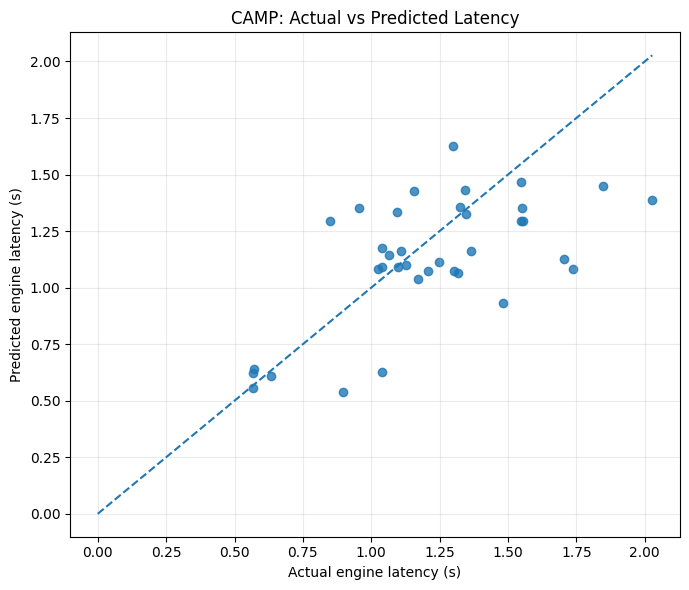

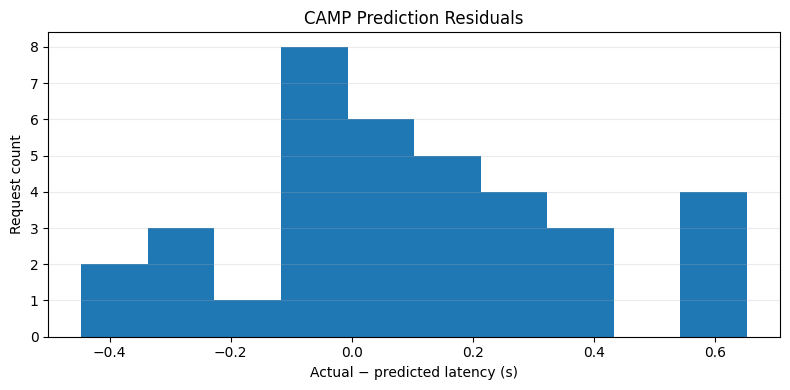

In [72]:
# Request-level prediction diagnostic plot for CAMP.
if len(camp_rows):
    plt.figure(figsize=(7, 6))
    plt.scatter(camp_rows["engine_latency_s"], camp_rows["predicted_engine_latency_s"], alpha=0.8)
    max_value = max(
        float(camp_rows["engine_latency_s"].max()),
        float(camp_rows["predicted_engine_latency_s"].max())
    )
    plt.plot([0, max_value], [0, max_value], linestyle="--")
    plt.xlabel("Actual engine latency (s)")
    plt.ylabel("Predicted engine latency (s)")
    plt.title("CAMP: Actual vs Predicted Latency")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 4))
    residual = camp_rows["engine_latency_s"] - camp_rows["predicted_engine_latency_s"]
    plt.hist(residual, bins=10)
    plt.xlabel("Actual − predicted latency (s)")
    plt.ylabel("Request count")
    plt.title("CAMP Prediction Residuals")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

In [73]:
OUTPUT_DIR = Path("/content/camp_scheduler_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Drop monotonic-clock columns from the portable CSV; keep elapsed measurements.
portable_results = results_df.drop(columns=["enqueue_perf", "completion_perf"], errors="ignore")
portable_results.to_csv(OUTPUT_DIR / "camp_scheduler_request_results.csv", index=False)
summary_df.to_csv(OUTPUT_DIR / "camp_scheduler_summary.csv", index=False)
comparison_df.to_csv(OUTPUT_DIR / "camp_scheduler_comparison.csv", index=False)
if len(predictor_report):
    predictor_report.to_csv(OUTPUT_DIR / "camp_predictor_benchmark_metrics.csv", index=False)

run_metadata = {
    "project": "CAMP - Calibration-Aware ML-Predictive Scheduling",
    "model_id": MODEL_ID,
    "gpu": torch.cuda.get_device_name(0),
    "gpu_memory_gib": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "selected_predictor": SELECTED_MODEL_NAME,
    "predictor_features": FEATURES,
    "calibration_residual_margin_s": CALIBRATION_MARGIN_S,
    "pilot_engine_latency_slo_s": SLO_TARGET_S,
    "fixed_k": FIXED_K,
    "adaptive_concurrency": [MIN_ADAPTIVE_K, MAX_ADAPTIVE_K],
    "aging_tau_s": AGING_TAU_S,
    "max_wait_priority_s": MAX_WAIT_PRIORITY_S,
    "benchmark_requests_per_workload": {
        str(k): int(v) for k, v in benchmark_df.groupby("workload_type").size().items()
    },
    "warning": "Small pilot benchmark only; repeat with larger independent traces before making research claims."
}
(OUTPUT_DIR / "camp_scheduler_run_metadata.json").write_text(json.dumps(run_metadata, indent=2))

print("Saved results to:", OUTPUT_DIR)
for file_path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{file_path.name:42s} {file_path.stat().st_size / 1024:8.1f} KB")

Saved results to: /content/camp_scheduler_results
camp_predictor_benchmark_metrics.csv            0.2 KB
camp_scheduler_comparison.csv                   1.8 KB
camp_scheduler_request_results.csv             61.6 KB
camp_scheduler_run_metadata.json                0.9 KB
camp_scheduler_summary.csv                      4.1 KB


In [74]:
# Download experiment evidence to your computer.
from google.colab import files

for filename in [
    "camp_scheduler_request_results.csv",
    "camp_scheduler_summary.csv",
    "camp_scheduler_comparison.csv",
    "camp_scheduler_run_metadata.json",
    "camp_predictor_benchmark_metrics.csv",
]:
    result_path = OUTPUT_DIR / filename
    if result_path.exists():
        files.download(str(result_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>